<a href="https://colab.research.google.com/github/revak18/science_fair_2026/blob/main/science_fair_2026_DRAFT_Dec28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:
# @title 1. SETUP & CONFIGURATION
# ==========================================
# 1. SETUP & CONFIGURATION
# ==========================================
import os
import sys
import shutil
import zipfile
import requests
import numpy as np
import pandas as pd
import pulp
import matplotlib.pyplot as plt
from datetime import timedelta
from google.colab import drive

# Mount Drive
drive.mount("/content/drive")

# Configuration
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
RESULTS_FILE = "final_scientific_results_optimized.csv"

# Make directories
for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
    os.makedirs(d, exist_ok=True)

# Simulation Settings
REGIONS = ["PJME", "COMED", "AEP", "DAYTON", "DOM"] # Grid Sub-regions to study-------------------------------------------------------------------
AI_LOAD_LEVELS = [0.10, 0.20, 0.30]
HORIZON_HOURS = 48

# --- UPDATED SETTINGS FOR ROBUSTNESS ---
N_TRIALS = 1          # CHANGED: Increased from 1 to 50 for statistical robustness------------------------------------------------------------------
DROUGHT_FACTOR = 1.0   # Set to 1.2 or 1.5 to simulate drought
PLANT_SIZE_MW = 500.0  # For the "Power Plant Equivalent" chart

# --- NEW: PARETO FRONTIER WEIGHTS ---
# Weights for water penalty in objective: Minimize C_gas + (weight * W_peak)
# 0.0 = Pure Gas Optimization, 0.1 = Water Conservative
PARETO_WEIGHTS = list(np.linspace(0.0, 1.0, 21))

# HEATWAVE SCENARIOS
HEATWAVE_SCENARIOS = [False, True]   # False=normal weather, True=heatwave

# proxy for congestion
IMPORT_LIMIT_FRACS = [0.0, 0.1, 0.2]  # fraction of L_max that can be imported

# Kaggle Credentials (Update if needed, or rely on manual upload)
os.environ['KAGGLE_USERNAME'] = "revakaggle"
os.environ['KAGGLE_KEY'] = "KGAT_ed225b90e0bddb93c8beeb022b1a9d88"

print(f"Setup Complete. Data Directory: {BASE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup Complete. Data Directory: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data


In [ ]:
# @title 2. DATA DOWNLOADERS (Run Once)
# ==========================================
# 2. DATA DOWNLOADERS (Run Once)
# ==========================================
def download_data_if_missing():
    # A. Grid Load (Kaggle)
    if not os.listdir(HOURLY_LOAD_DIR):
        print("Downloading Grid Load Data from Kaggle...")
        os.system(f'kaggle datasets download -d robikscube/hourly-energy-consumption -p "{BASE_DIR}"')
        zip_path = os.path.join(BASE_DIR, "hourly-energy-consumption.zip")
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(HOURLY_LOAD_DIR)
        print("Grid Data Extracted.")

    # B. Water Data (HydroShare)
    # Direct URL to the specific csv to save time (skipping the 1.3GB bag if possible)
    # If full bag is needed, use your original code. Here we assume the CSV exists or we download the bag.
    water_csv_name = "Water_IMPACT-Data_Consumption_2020.csv"
    water_csv_path = os.path.join(BASE_DIR, water_csv_name)

    if not os.path.exists(water_csv_path):
        print("Downloading Water IMPACT Data...")
        # (This is the URL for the full bag, uncomment if needed)
        # url = "https://www.hydroshare.org/hsapi/resource/2f54448714554f83b9655da108f0fd3f/"
        # For now, we assume you have placed the CSV in the folder as per previous logs.
        # If not, upload it manually to Drive.
        pass

download_data_if_missing()

In [37]:
# @title 3. DATA LOADERS (WITH EXPLICIT CLEANING + REPRODUCIBLE QC)
# ==========================================
# 3. DATA LOADERS
# ==========================================

def qc_report(series, name, clip_lo=None, clip_hi=None):
    """Small numeric QC summary for reproducibility logs."""
    s = pd.Series(series).copy()
    out = {
        "name": name,
        "n": int(s.size),
        "nan": int(s.isna().sum()),
        "nan_pct": float(s.isna().mean() * 100.0),
        "min": float(np.nanmin(s.values)),
        "p01": float(np.nanpercentile(s.values, 1)),
        "p50": float(np.nanpercentile(s.values, 50)),
        "p99": float(np.nanpercentile(s.values, 99)),
        "max": float(np.nanmax(s.values)),
    }
    if clip_lo is not None or clip_hi is not None:
        lo = -np.inf if clip_lo is None else clip_lo
        hi =  np.inf if clip_hi is None else clip_hi
        out["clipped_count"] = int(((s < lo) | (s > hi)).sum())
        out["clip_lo"] = clip_lo
        out["clip_hi"] = clip_hi
    return out


def load_ba_load(region: str):
    """
    Loads Grid Load and applies explicit, reproducible cleaning:
      - parse timestamps
      - de-duplicate timestamps via mean
      - reindex to full hourly timeline
      - remove negative loads
      - clip extreme outliers (0.1%–99.9% quantiles)
      - fill short gaps (<=3 hours) by interpolation, then edge ffill/bfill
    """
    print(f"   -> Loading Grid Load for {region}...")
    fname = f"{region}_hourly.csv"
    path = os.path.join(HOURLY_LOAD_DIR, fname)

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    df = pd.read_csv(path, parse_dates=["Datetime"])

    # Rename value column to 'load_MW'
    mw_col = [c for c in df.columns if c.endswith("_MW")]
    if len(mw_col) == 0:
        raise ValueError(f"No *_MW column found in {path}. Columns: {list(df.columns)}")
    df = df.rename(columns={mw_col[0]: "load_MW"})

    # Index & de-duplicate
    df = df.set_index("Datetime").sort_index()
    df["load_MW"] = pd.to_numeric(df["load_MW"], errors="coerce")
    df = df.groupby(df.index).mean(numeric_only=True)

    # Reindex to complete hourly timeline
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="H")
    df = df.reindex(full_idx)

    # Remove negatives
    df.loc[df["load_MW"] < 0, "load_MW"] = np.nan

    # Clip outliers (documentable thresholds)
    lo = float(df["load_MW"].quantile(0.001))
    hi = float(df["load_MW"].quantile(0.999))
    df["load_MW"] = df["load_MW"].clip(lo, hi)

    # Fill only short gaps, then edges
    df["load_MW"] = df["load_MW"].interpolate(limit=3).ffill().bfill()

    return df


def load_water_intensity(region: str):
    """
    Loads Water Data and applies explicit, reproducible cleaning:
      - map sub-regions to BA codes where needed (PJME/COMED/etc -> PJM)
      - filter to BA
      - de-duplicate dates via mean
      - convert to m3/MWh
      - remove negatives
      - clip extreme outliers (0–99.9% quantile)
      - resample to hourly + fill short gaps (<=3 hours)
    """
    print(f"   -> Loading Water Intensity for {region}...")

    REGION_MAP = {
        "PJME": "PJM", "PJMW": "PJM", "COMED": "PJM", "DAYTON": "PJM",
        "AEP": "PJM", "DOM": "PJM", "DUQ": "PJM", "FE": "PJM",
        "DEOK": "PJM", "NI": "PJM", "PJM": "PJM",
        "CISO": "CISO", "ERCOT": "ERCO", "SPP": "SWPP"
    }
    search_region = REGION_MAP.get(region, region)

    path = os.path.join(BASE_DIR, "Water_IMPACT-Data_Consumption_2020.csv")
    if not os.path.exists(path):
        path = os.path.join(WATER_IMPACT_DIR, "Water_IMPACT-Data_Consumption_2020.csv")

    if not os.path.exists(path):
        raise FileNotFoundError(f"Water file not found at {path}")

    df = pd.read_csv(path, parse_dates=["date"])

    # Filter by Region
    col = "balancing_authority" if "balancing_authority" in df.columns else "ba_code"
    df = df[df[col] == search_region].copy()
    if df.empty:
        raise ValueError(f"Region '{search_region}' not found in Water Data.")

    # Index & de-duplicate
    df = df.set_index("date").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    # Select water consumption column
    target = "wci_primary" if "wci_primary" in df.columns else "w_consume_l_per_kwh"

    # Convert to numeric and to m3/MWh
    # If source is liters/kWh: 1 L/kWh = 1 m3/MWh
    df["w_m3_per_MWh"] = pd.to_numeric(df[target], errors="coerce") * float(DROUGHT_FACTOR)

    # Remove negatives
    df.loc[df["w_m3_per_MWh"] < 0, "w_m3_per_MWh"] = np.nan

    # Clip high outliers for stability (keep non-negative)
    hi = float(df["w_m3_per_MWh"].quantile(0.999))
    df["w_m3_per_MWh"] = df["w_m3_per_MWh"].clip(0, hi)

    # Resample to hourly + fill short gaps
    df_clean = df[["w_m3_per_MWh"]].resample("H").mean()
    df_clean["w_m3_per_MWh"] = df_clean["w_m3_per_MWh"].interpolate(limit=3).ffill().bfill()

    return df_clean


def build_stressed_window(load_df, water_df, horizon_hours,
                          top_k_candidates=30,
                          min_separation_hours=24,
                          max_fill_hours=3,
                          max_missing_pct_load=1.0,
                          max_missing_pct_water=5.0):
    """
    Find a 'stressed' (high-load) window that ALSO meets data-quality thresholds.

    Strategy:
      1) Compute 7-day rolling mean of load and take the top_k candidate peak times.
      2) For each candidate, extract a horizon_hours window around it.
      3) Shift the load timestamps to match the water_df year (e.g., 2020).
      4) Merge load + water and ONLY fill short gaps (<= max_fill_hours).
      5) Accept the first window that has:
           - no remaining NaNs
           - missing pct <= thresholds for both series
           - (implicitly) no long gaps, since long gaps will remain NaN after limited fill
    """

    print("   -> Extracting Peak Window (quality-gated search)...")

    # --- helper: remove near-duplicate candidate peaks so we don't test almost-identical windows ---
    def _dedupe_candidates(times, min_sep_hours):
        kept = []
        for t in times:
            if all(abs((t - k).total_seconds()) >= min_sep_hours * 3600 for k in kept):
                kept.append(t)
        return kept

    # 1) Candidate peaks via 7-day rolling mean (smooths noisy spikes)
    rolling = load_df["load_MW"].rolling(window=24 * 7, min_periods=24).mean()

    # if rolling is all-NaN, fail early
    if rolling.dropna().empty:
        raise ValueError("Rolling mean load is empty/all-NaN; cannot find peak window.")

    candidate_times = list(rolling.nlargest(top_k_candidates).index)
    candidate_times = _dedupe_candidates(candidate_times, min_separation_hours)

    target_year = int(water_df.index.year[0])  # typically 2020

    # 2) Try candidates until one passes quality checks
    for rank, peak_time in enumerate(candidate_times, start=1):
        half = timedelta(hours=horizon_hours // 2)
        start = peak_time - half
        end = start + timedelta(hours=horizon_hours - 1)

        load_slice = load_df.loc[start:end].copy()
        if load_slice.empty or len(load_slice) < horizon_hours * 0.8:
            # not enough data in this window
            continue

        # Shift to target year to align with water year
        new_dates = []
        for d in load_slice.index:
            try:
                new_d = d.replace(year=target_year)
            except ValueError:
                new_d = d.replace(year=target_year, month=3, day=1)  # leap-day fix
            new_dates.append(new_d)
        load_slice.index = pd.DatetimeIndex(new_dates)

        # Build window dataframe
        window_df = pd.DataFrame(index=load_slice.index)
        window_df["L_base_MW"] = pd.to_numeric(load_slice["load_MW"], errors="coerce")
        window_df["water_m3_per_mwh"] = water_df["w_m3_per_MWh"].reindex(window_df.index)

        # --- Limited filling: only small gaps ---
        # Load
        window_df["L_base_MW"] = window_df["L_base_MW"].interpolate(limit=max_fill_hours)
        window_df["L_base_MW"] = window_df["L_base_MW"].ffill(limit=max_fill_hours).bfill(limit=max_fill_hours)

        # Water
        window_df["water_m3_per_mwh"] = window_df["water_m3_per_mwh"].interpolate(limit=max_fill_hours)
        window_df["water_m3_per_mwh"] = window_df["water_m3_per_mwh"].ffill(limit=max_fill_hours).bfill(limit=max_fill_hours)

        # --- Quality checks ---
        miss_load_pct = float(window_df["L_base_MW"].isna().mean() * 100.0)
        miss_water_pct = float(window_df["water_m3_per_mwh"].isna().mean() * 100.0)

        if (miss_load_pct <= max_missing_pct_load and
            miss_water_pct <= max_missing_pct_water and
            not window_df["L_base_MW"].isna().any() and
            not window_df["water_m3_per_mwh"].isna().any()):

            print(f"      Selected candidate #{rank} (peak_time={peak_time}) "
                  f"with missing load={miss_load_pct:.2f}%, water={miss_water_pct:.2f}%")
            return window_df

        # otherwise reject and continue searching
        # (Optional debug)
        # print(f"      Reject candidate #{rank}: missing load={miss_load_pct:.2f}%, water={miss_water_pct:.2f}%")

    # 3) If none pass, fail (main loop will skip this region)
    raise ValueError(
        f"No {horizon_hours}h window passed quality thresholds after testing "
        f"{len(candidate_times)} candidates. Try relaxing thresholds or increasing top_k_candidates."
    )



In [38]:
# @title 4. WORKLOAD GENERATION & SOLVER (THOROUGHNESS UPGRADE; COMPATIBLE WITH SIMPLIFIED MAIN LOOP)

import numpy as np
import pulp
import time

# --- 1) WORKLOAD GENERATORS ---

def build_online_ai_load(window_df, L_max, fraction, rng):
    """Online (non-deferrable) AI load: diurnal pattern + noise."""
    base = fraction * L_max
    L_online = np.zeros(len(window_df))
    for t, ts in enumerate(window_df.index):
        mult = 1.3 if 9 <= ts.hour <= 21 else 0.4   # higher daytime
        noise = rng.uniform(0.9, 1.1)
        L_online[t] = base * mult * noise
    return L_online


def _sample_slack_hours(rng, regime="mixed"):
    """Job slack (deadline flexibility) distribution in hours."""
    if regime == "tight":
        return int(rng.integers(1, 5))        # 1–4h
    if regime == "medium":
        return int(rng.integers(6, 13))       # 6–12h
    if regime == "loose":
        return int(rng.integers(12, 25))      # 12–24h

    # mixed: mostly medium, some tight/loose
    u = rng.random()
    if u < 0.2:
        return int(rng.integers(1, 5))
    if u < 0.85:
        return int(rng.integers(6, 13))
    return int(rng.integers(12, 25))


def generate_jobs_stochastic(T, t_peak, L_max, rng,
                            base_rate=0.6, peak_amp=1.5, peak_sigma=8,
                            slack_regime="mixed"):
    """
    Stochastic job arrivals:
      - Poisson arrivals each hour
      - arrival rate increases around t_peak
      - job sizes and durations are a mixture distribution
      - deadlines come from sampled slack
    """
    jobs = []

    size_mix = [
        (0.65, (0.01, 0.03), (1, 4)),    # small
        (0.28, (0.03, 0.06), (4, 10)),   # medium
        (0.07, (0.06, 0.10), (10, 18)),  # large
    ]

    for t in range(T):
        lam = base_rate * (1.0 + peak_amp * np.exp(-0.5 * ((t - t_peak) / peak_sigma) ** 2))
        n_new = rng.poisson(lam)

        for _ in range(n_new):
            u = rng.random()
            cum = 0.0
            p_frac, dur = None, None
            for prob, (p_lo, p_hi), (d_lo, d_hi) in size_mix:
                cum += prob
                if u <= cum:
                    p_frac = float(rng.uniform(p_lo, p_hi))
                    dur = int(rng.integers(d_lo, d_hi + 1))
                    break

            power = p_frac * L_max
            slack = _sample_slack_hours(rng, regime=slack_regime)

            release = t
            deadline = min(T, release + dur + slack)

            # keep only feasible jobs
            if deadline - dur < release:
                continue

            jobs.append({
                "power": power,
                "duration": dur,
                "release": release,
                "deadline": deadline
            })

    return jobs


def build_ambient_temperature(index, rng, heatwave=False):
    """Synthetic ambient temperature (°C): diurnal sinusoid + noise + heatwave shift."""
    hours = np.array([ts.hour for ts in index], dtype=float)
    Tamb = 30.0 + 6.0 * np.sin(2 * np.pi * (hours - 15) / 24.0)
    Tamb = Tamb + rng.normal(0.0, 1.0, size=len(index))
    if heatwave:
        Tamb = Tamb + 5.0
    return Tamb


# --- 2) SOLVER (logs solve time + model size; consistent gas trace with import limit) ---

def solve_milp(L_base, L_online, jobs, w_vec,
               alpha=0.3, rho=0.15, water_weight=0.001,
               Tamb=None, include_thermal=False,
               tau_hours=6.0, T_init=27.0, T_max=35.0,
               temp_ref=30.0, wue_base_m3_per_MWh=0.20, wue_temp_slope=0.03,
               b_temp_per_MW=8e-5,
               import_limit_MW=0.0):

    T = len(L_base)
    L_max = float(np.max(L_base))
    C_non = np.full(T, (1.0 - alpha) * L_max)

    prob = pulp.LpProblem("Flex", pulp.LpMinimize)

    # Decision vars
    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)

    # Thermal vars (optional)
    if include_thermal:
        T_dc = pulp.LpVariable.dicts("T_dc", range(T), lowBound=-50)  # no upBound to reduce infeasible
        T_excess = pulp.LpVariable.dicts("T_excess", range(T), lowBound=0)
        W_cool = pulp.LpVariable.dicts("W_cool", range(T), lowBound=0)

        temp_violation = pulp.LpVariable.dicts("temp_violation", range(T), lowBound=0)
        TEMP_PENALTY = 1e6  # very large: only violate temperature if absolutely necessary

        a = float(np.exp(-1.0 / tau_hours))
        prob += T_dc[0] == float(T_init)

    # Job vars
    x, y = {}, {}
    for j, job in enumerate(jobs):
        for t in range(T):
            x[j, t] = pulp.LpVariable(f"x_{j}_{t}", 0, 1, cat=pulp.LpBinary)  # active
            y[j, t] = pulp.LpVariable(f"y_{j}_{t}", 0, 1, cat=pulp.LpBinary)  # start

    # Objective
    if include_thermal:
        prob += C_gas + (water_weight * W_peak) + TEMP_PENALTY * pulp.lpSum(temp_violation[t] for t in range(T))
    else:
        prob += C_gas + (water_weight * W_peak)

    # Job constraints: single-start + contiguity
    for j, job in enumerate(jobs):
        d = int(job["duration"])
        r = int(job["release"])
        D = int(job["deadline"])

        valid_starts = list(range(r, D - d + 1))
        if len(valid_starts) == 0:
            # Return infeasible with compute metadata (no solve)
            return {
                "status": "Infeasible",
                "solve_time_s": 0.0,
                "n_vars": 0,
                "n_cons": 0,
                "n_jobs": int(len(jobs)),
                "T": int(T),
            }

        prob += pulp.lpSum(y[j, t] for t in valid_starts) == 1

        for t in range(T):
            recent_starts = [y[j, k] for k in range(max(0, t - d + 1), t + 1) if k in valid_starts]
            prob += x[j, t] == pulp.lpSum(recent_starts)

    # System constraints
    for t in range(T):
        L_batch = pulp.lpSum(jobs[j]["power"] * x[j, t] for j in range(len(jobs)))
        L_total = (1 + rho) * L_base[t] + L_online[t] + L_batch

        # Adequacy (import limit proxy)
        prob += L_total <= C_non[t] + C_gas + import_limit_MW

        # Water peak
        if include_thermal:
            L_dc = L_online[t] + L_batch
            amb = float(Tamb[t]) if Tamb is not None else 30.0

            if t < T - 1:
                prob += T_dc[t + 1] == a * T_dc[t] + (1 - a) * amb + b_temp_per_MW * L_dc

            prob += T_dc[t] <= float(T_max) + temp_violation[t]
            prob += T_excess[t] >= T_dc[t] - float(temp_ref)
            prob += W_cool[t] == wue_base_m3_per_MWh * L_dc + wue_temp_slope * T_excess[t]

            prob += W_peak >= (w_vec[t] * L_total) + W_cool[t]
        else:
            prob += W_peak >= w_vec[t] * L_total

    # --- Solve + timing + size logging ---
    n_vars = len(prob.variables())
    n_cons = len(prob.constraints)

    t0 = time.perf_counter()
    prob.solve(pulp.PULP_CBC_CMD(msg=False))
    solve_time_s = time.perf_counter() - t0

    if pulp.LpStatus[prob.status] != "Optimal":
        return {
            "status": "Infeasible",
            "solve_time_s": float(solve_time_s),
            "n_vars": int(n_vars),
            "n_cons": int(n_cons),
            "n_jobs": int(len(jobs)),
            "T": int(T),
        }

    # Reconstruct traces
    L_batch_opt = np.zeros(T)
    for t in range(T):
        L_batch_opt[t] = sum(jobs[j]["power"] * (pulp.value(x[j, t]) or 0.0) for j in range(len(jobs)))

    L_total_opt = (1 + rho) * L_base + L_online + L_batch_opt

    # gas trace consistent with baseline and constraint
    g_gas_opt = np.maximum(0, L_total_opt - (C_non + import_limit_MW))

    if include_thermal:
        W_cool_opt = np.array([(pulp.value(W_cool[t]) or 0.0) for t in range(T)], dtype=float)
        w_rate_opt = (w_vec * L_total_opt) + W_cool_opt
        tv_sum = float(sum((pulp.value(temp_violation[t]) or 0.0) for t in range(T)))
        tv_max = float(max((pulp.value(temp_violation[t]) or 0.0) for t in range(T)))
    else:
        W_cool_opt = np.zeros(T)
        w_rate_opt = w_vec * L_total_opt
        tv_sum, tv_max = 0.0, 0.0

    return {
        "status": "Optimal",
        "C_peak": float(pulp.value(C_gas) or 0.0),
        "W_peak": float(pulp.value(W_peak) or 0.0),
        "temp_violation_sum": tv_sum,
        "temp_violation_max": tv_max,
        "L_batch": L_batch_opt,
        "L_total": L_total_opt,
        "g_gas": g_gas_opt,
        "w_rate": w_rate_opt,
        "W_cool": W_cool_opt,
        # compute/performance metadata
        "solve_time_s": float(solve_time_s),
        "n_vars": int(n_vars),
        "n_cons": int(n_cons),
        "n_jobs": int(len(jobs)),
        "T": int(T),
    }


# --- 3) PROBABILISTIC ADEQUACY + WATER RISK (adds water-factor & renewable intermittency uncertainty) ---

def adequacy_risk_metrics(L_total, C_non, C_gas_value, rng,
                         sigma_load=0.03,
                         forced_outage_rate=0.03,
                         # NEW uncertainty knobs:
                         sigma_w=0.10,              # water factor multiplicative uncertainty (lognormal-ish)
                         ren_drop_prob=0.05,        # probability of non-gas dip each hour
                         ren_drop_severity=0.15,    # dip severity (fraction of C_non)
                         n_scen=200,
                         w_vec=None):
    """
    Reliability + water-risk under uncertainty:
      - load forecast error (multiplicative)
      - forced outage of gas capacity (hourly Bernoulli)
      - renewable/non-gas intermittency: reduce C_non randomly
      - OPTIONAL water factor uncertainty if w_vec provided:
          w_t_scen = w_vec[t] * (1 + Normal(0, sigma_w)), clipped >= 0
    Returns:
      LOLE (hours), EUE (MWh), plus optional W_peak distribution stats if w_vec provided.
    """
    T = len(L_total)
    lole_hours, eue_mwh = [], []
    w_peak_list = []

    for _ in range(n_scen):
        # load uncertainty
        eps = rng.normal(0.0, sigma_load, size=T)
        Ls = L_total * (1.0 + eps)

        # gas availability (forced outage)
        gas_available = C_gas_value * (1.0 - (rng.random(T) < forced_outage_rate).astype(float))

        # non-gas intermittency (simple stress model)
        ren_drop = (rng.random(T) < ren_drop_prob).astype(float) * ren_drop_severity
        Cnon_s = C_non * (1.0 - ren_drop)

        shortfall = np.maximum(0.0, Ls - (Cnon_s + gas_available))
        lole_hours.append(np.sum(shortfall > 0))
        eue_mwh.append(np.sum(shortfall))

        # optional water-peak under uncertain water factors
        if w_vec is not None:
            w_mult = 1.0 + rng.normal(0.0, sigma_w, size=T)
            w_mult = np.clip(w_mult, 0.0, None)
            w_s = w_vec * w_mult
            w_peak_list.append(float(np.max(w_s * Ls)))

    out = {
        "LOLE_hours_mean": float(np.mean(lole_hours)),
        "EUE_MWh_mean": float(np.mean(eue_mwh)),
        "LOLE_hours_p95": float(np.percentile(lole_hours, 95)),
        "EUE_MWh_p95": float(np.percentile(eue_mwh, 95)),
    }

    if w_vec is not None and len(w_peak_list) > 0:
        out.update({
            "Wpeak_mean": float(np.mean(w_peak_list)),
            "Wpeak_p95": float(np.percentile(w_peak_list, 95)),
        })

    return out


In [41]:
# @title 5. MAIN EXECUTION LOOP (THOROUGHNESS UPGRADE: QC LOG + SOLVE TIMES + UNCERTAINTIES)

from itertools import product
import os
import numpy as np
import pandas as pd

print("\n=== STARTING MULTI-REGION STUDY ===")
results = []
all_traces = []  # Storage for full time-series data

# Scenario grid (flat loop later)
scenario_grid = list(product(IMPORT_LIMIT_FRACS, HEATWAVE_SCENARIOS, PARETO_WEIGHTS))

# QC report file (append mode)
qc_path = os.path.join(BASE_DIR, "data_qc_report.csv")

for region in REGIONS:
    print(f"\nProcessing Region: {region}...")
    try:
        # 1) Load Data
        load_df = load_ba_load(region)
        water_df = load_water_intensity(region)

        # 2) Build Window (quality-gated search happens inside build_stressed_window)
        window = build_stressed_window(load_df, water_df, HORIZON_HOURS)

        # --- Save QC row for reproducibility (per region window) ---
        # qc_report comes from your Data Loader cell
        qc_rows = [
            qc_report(window["L_base_MW"], f"{region}_window_L_base_MW", clip_lo=0, clip_hi=None),
            qc_report(window["water_m3_per_mwh"], f"{region}_window_water_m3_per_mwh", clip_lo=0, clip_hi=None),
        ]
        qc_df = pd.DataFrame(qc_rows)
        qc_df.to_csv(qc_path, mode="a", header=not os.path.exists(qc_path), index=False)

        # Arrays
        L_base = window["L_base_MW"].values
        w_vec = window["water_m3_per_mwh"].values
        T = len(L_base)
        L_max = float(np.max(L_base))

        # Identify Peak Index for job clustering
        base_total = 1.15 * L_base
        t_peak = int(np.argmax(base_total))

        # 3) Run Scenarios
        for ai_frac in AI_LOAD_LEVELS:
            print(f"   -> AI Level: {ai_frac:.2f}")

            for trial in range(N_TRIALS):
                rng = np.random.default_rng(trial)

                # --- Build ONE workload per trial (reused across all weights/import/heatwave) ---
                L_online = build_online_ai_load(window, L_max, ai_frac, rng)
                jobs = generate_jobs_stochastic(T, t_peak, L_max, rng, slack_regime="mixed")

                # --- Baseline (naive ASAP schedule) ---
                L_naive_batch = np.zeros(T)
                for job in jobs:
                    start_t = job["release"]
                    end_t = min(start_t + job["duration"], T)
                    L_naive_batch[start_t:end_t] += job["power"]

                L_total_naive = (1.15 * L_base) + L_online + L_naive_batch
                C_non_gas = (1.0 - 0.3) * L_max

                # Baseline water peak independent of import limit
                w_base_trace = w_vec * L_total_naive
                w_base = float(np.max(w_base_trace))

                # Precompute ambient temps (same RNG per trial; two modes)
                Tamb_by_hw = {
                    hw: build_ambient_temperature(window.index, rng, heatwave=hw)
                    for hw in HEATWAVE_SCENARIOS
                }

                # --- Flat scenario loop ---
                for import_frac, heatwave, w_weight in scenario_grid:
                    import_limit_MW = float(import_frac) * L_max

                    # Baseline gas peak DOES depend on import limit (congestion proxy)
                    g_base_trace = np.maximum(0, L_total_naive - (C_non_gas + import_limit_MW))
                    c_base = float(np.max(g_base_trace))

                    # Solve optimized schedule
                    sol = solve_milp(
                        L_base, L_online, jobs, w_vec,
                        water_weight=float(w_weight),
                        Tamb=Tamb_by_hw[heatwave], include_thermal=True,
                        import_limit_MW=import_limit_MW
                    )

                    # Risk metrics under uncertainty (now includes optional water-factor + intermittency)
                    risk_base = adequacy_risk_metrics(
                        L_total_naive, C_non_gas*np.ones(T), c_base, rng,
                        w_vec=w_vec
                    )
                    if sol["status"] == "Optimal":
                        risk_opt = adequacy_risk_metrics(
                            sol["L_total"], C_non_gas*np.ones(T), sol["C_peak"], rng,
                            w_vec=w_vec
                        )

                        avoided_mw = c_base - sol["C_peak"]
                        water_saved_abs = w_base - sol["W_peak"]

                        results.append({
                            "region": region,
                            "ai_fraction": float(ai_frac),
                            "trial": int(trial),
                            "import_frac": float(import_frac),
                            "heatwave": int(heatwave),
                            "water_weight": float(w_weight),

                            "avoided_capacity_mw": float(avoided_mw),
                            "water_peak_m3h": float(sol["W_peak"]),
                            "baseline_capacity_mw": float(c_base),
                            "baseline_water_m3h": float(w_base),
                            "water_saved_absolute": float(water_saved_abs),

                            "plants_avoided": float(avoided_mw / PLANT_SIZE_MW),
                            "peak_reduction_pct": float((avoided_mw / c_base * 100) if c_base > 0 else 0),

                            # NEW: compute/performance details
                            "solve_time_s": float(sol.get("solve_time_s", 0.0)),
                            "n_vars": int(sol.get("n_vars", 0)),
                            "n_cons": int(sol.get("n_cons", 0)),
                            "n_jobs": int(sol.get("n_jobs", len(jobs))),
                            "T": int(sol.get("T", T)),

                            # Thermal diagnostics
                            "temp_violation_sum": float(sol.get("temp_violation_sum", 0.0)),
                            "temp_violation_max": float(sol.get("temp_violation_max", 0.0)),

                            # Reliability / adequacy risk metrics (baseline + optimized)
                            "LOLE_base_mean": risk_base["LOLE_hours_mean"],
                            "EUE_base_mean": risk_base["EUE_MWh_mean"],
                            "LOLE_base_p95": risk_base["LOLE_hours_p95"],
                            "EUE_base_p95": risk_base["EUE_MWh_p95"],
                            "Wpeak_base_mean_unc": risk_base.get("Wpeak_mean", np.nan),
                            "Wpeak_base_p95_unc":  risk_base.get("Wpeak_p95", np.nan),

                            "LOLE_opt_mean":  risk_opt["LOLE_hours_mean"],
                            "EUE_opt_mean":   risk_opt["EUE_MWh_mean"],
                            "LOLE_opt_p95":   risk_opt["LOLE_hours_p95"],
                            "EUE_opt_p95":    risk_opt["EUE_MWh_p95"],
                            "Wpeak_opt_mean_unc": risk_opt.get("Wpeak_mean", np.nan),
                            "Wpeak_opt_p95_unc":  risk_opt.get("Wpeak_p95", np.nan),
                        })

                        for t in range(T):
                            all_traces.append({
                                "region": region,
                                "ai_fraction": float(ai_frac),
                                "trial": int(trial),
                                "import_frac": float(import_frac),
                                "heatwave": int(heatwave),
                                "water_weight": float(w_weight),
                                "hour": int(t),

                                "L_grid": float(L_base[t]),
                                "L_online": float(L_online[t]),
                                "water_intensity": float(w_vec[t]),

                                "L_batch_base": float(L_naive_batch[t]),
                                "L_total_base": float(L_total_naive[t]),
                                "g_gas_base": float(g_base_trace[t]),
                                "w_rate_base": float(w_base_trace[t]),

                                "L_batch_opt": float(sol["L_batch"][t]),
                                "L_total_opt": float(sol["L_total"][t]),
                                "g_gas_opt": float(sol["g_gas"][t]),
                                "w_rate_opt": float(sol["w_rate"][t]),
                            })

                    else:
                        # still log infeasible cases with compute metadata + baseline risk
                        results.append({
                            "region": region,
                            "ai_fraction": float(ai_frac),
                            "trial": int(trial),
                            "import_frac": float(import_frac),
                            "heatwave": int(heatwave),
                            "water_weight": float(w_weight),

                            "avoided_capacity_mw": np.nan,
                            "water_peak_m3h": np.nan,
                            "baseline_capacity_mw": float(c_base),
                            "baseline_water_m3h": float(w_base),
                            "water_saved_absolute": np.nan,

                            "plants_avoided": np.nan,
                            "peak_reduction_pct": np.nan,

                            "solve_time_s": float(sol.get("solve_time_s", 0.0)),
                            "n_vars": int(sol.get("n_vars", 0)),
                            "n_cons": int(sol.get("n_cons", 0)),
                            "n_jobs": int(sol.get("n_jobs", len(jobs))),
                            "T": int(sol.get("T", T)),

                            "temp_violation_sum": float(sol.get("temp_violation_sum", 0.0)),
                            "temp_violation_max": float(sol.get("temp_violation_max", 0.0)),

                            "LOLE_base_mean": risk_base["LOLE_hours_mean"],
                            "EUE_base_mean": risk_base["EUE_MWh_mean"],
                            "LOLE_base_p95": risk_base["LOLE_hours_p95"],
                            "EUE_base_p95": risk_base["EUE_MWh_p95"],
                            "Wpeak_base_mean_unc": risk_base.get("Wpeak_mean", np.nan),
                            "Wpeak_base_p95_unc":  risk_base.get("Wpeak_p95", np.nan),

                            "LOLE_opt_mean": np.nan,
                            "EUE_opt_mean": np.nan,
                            "LOLE_opt_p95": np.nan,
                            "EUE_opt_p95": np.nan,
                            "Wpeak_opt_mean_unc": np.nan,
                            "Wpeak_opt_p95_unc":  np.nan,
                        })

                        print(f"Warning: {sol['status']} for {region} AI={ai_frac} trial={trial} "
                              f"import={import_frac:.2f} heatwave={heatwave} w={w_weight:.3f}")

    except Exception as e:
        print(f"!!! Error processing {region}: {e}")

# ==========================================
# SAVE RESULTS
# ==========================================
res_df = pd.DataFrame(results)
res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
print(f"\nStudy Complete. Summary results saved to {RESULTS_FILE}")

if all_traces:
    trace_file = "full_simulation_traces.csv"
    trace_df = pd.DataFrame(all_traces)
    trace_df.to_csv(os.path.join(BASE_DIR, trace_file), index=False)
    print(f"Full Traces saved to {trace_file} ({len(trace_df)} rows)")

print(f"QC report appended to: {qc_path}")



=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...


/tmp/ipython-input-3865309690.py:60: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_idx = pd.date_range(df.index.min(), df.index.max(), freq="H")


   -> Loading Water Intensity for PJME...


/tmp/ipython-input-3865309690.py:132: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df[["w_m3_per_MWh"]].resample("H").mean()


   -> Extracting Peak Window (quality-gated search)...
      Selected candidate #1 (peak_time=2006-08-05 02:00:00) with missing load=0.00%, water=0.00%
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...


/tmp/ipython-input-3865309690.py:60: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_idx = pd.date_range(df.index.min(), df.index.max(), freq="H")
/tmp/ipython-input-3865309690.py:132: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df[["w_m3_per_MWh"]].resample("H").mean()


... (9 outputs left out)

/tmp/ipython-input-3865309690.py:60: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_idx = pd.date_range(df.index.min(), df.index.max(), freq="H")


   -> Loading Water Intensity for DOM...


/tmp/ipython-input-3865309690.py:132: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df[["w_m3_per_MWh"]].resample("H").mean()


   -> Extracting Peak Window (quality-gated search)...
      Selected candidate #1 (peak_time=2018-01-08 10:00:00) with missing load=0.00%, water=0.00%
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Study Complete. Summary results saved to final_scientific_results_optimized.csv
Full Traces saved to full_simulation_traces.csv (90720 rows)
QC report appended to: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/data_qc_report.csv



=== RUNNING BENCHMARK on region=PJME ai_frac=0.1 ===
   -> Loading Grid Load for PJME...


/tmp/ipython-input-3865309690.py:60: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_idx = pd.date_range(df.index.min(), df.index.max(), freq="H")


   -> Loading Water Intensity for PJME...


/tmp/ipython-input-3865309690.py:132: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df[["w_m3_per_MWh"]].resample("H").mean()



--- Horizon 24h ---
   -> Extracting Peak Window (quality-gated search)...
      Selected candidate #1 (peak_time=2006-08-05 02:00:00) with missing load=0.00%, water=0.00%
base_rate=0.40, slack=tight infeasible=0/5
base_rate=0.40, slack=mixed infeasible=0/5
base_rate=0.40, slack=loose infeasible=0/5
base_rate=1.20, slack=tight infeasible=0/5
base_rate=1.20, slack=mixed infeasible=0/5
base_rate=1.20, slack=loose infeasible=0/5

--- Horizon 48h ---
   -> Extracting Peak Window (quality-gated search)...
      Selected candidate #1 (peak_time=2006-08-05 02:00:00) with missing load=0.00%, water=0.00%
base_rate=0.40, slack=tight infeasible=0/5
base_rate=0.40, slack=mixed infeasible=0/5
base_rate=0.40, slack=loose infeasible=0/5
base_rate=1.20, slack=tight infeasible=0/5
base_rate=1.20, slack=mixed infeasible=0/5
base_rate=1.20, slack=loose infeasible=0/5

Benchmark saved to: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/milp_sc

,horizon_hours,base_rate,slack_regime,trials,infeasible,infeasible_rate,n_jobs_mean,n_vars_mean,n_cons_mean,solve_time_mean,solve_time_p95,solve_time_max
9,48,1.2,loose,5,0,0.0,89.2,5977.0,4658.8,1.780966,2.471259,2.556408
6,48,0.4,loose,5,0,0.0,32.8,2302.6,1895.2,1.665974,2.540781,2.557107
10,48,1.2,mixed,5,0,0.0,89.6,5339.8,4678.4,0.533132,0.730225,0.738968
7,48,0.4,mixed,5,0,0.0,32.4,2045.0,1875.6,0.428172,0.666522,0.687032
11,48,1.2,tight,5,0,0.0,89.2,4786.8,4658.8,0.288859,0.320732,0.327804
3,24,1.2,loose,5,0,0.0,46.8,1804.4,1314.0,0.286228,0.358714,0.365677
4,24,1.2,mixed,5,0,0.0,44.8,1528.8,1264.0,0.175728,0.267846,0.290909
8,48,0.4,tight,5,0,0.0,32.8,1880.6,1895.2,0.138971,0.150494,0.151349
0,24,0.4,loose,5,0,0.0,14.2,620.6,499.0,0.114842,0.139276,0.140361
5,24,1.2,tight,5,0,0.0,46.8,1381.8,1314.0,0.097907,0.115711,0.118095


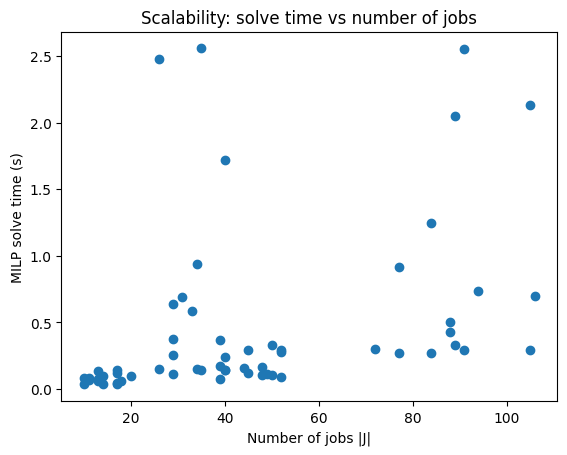

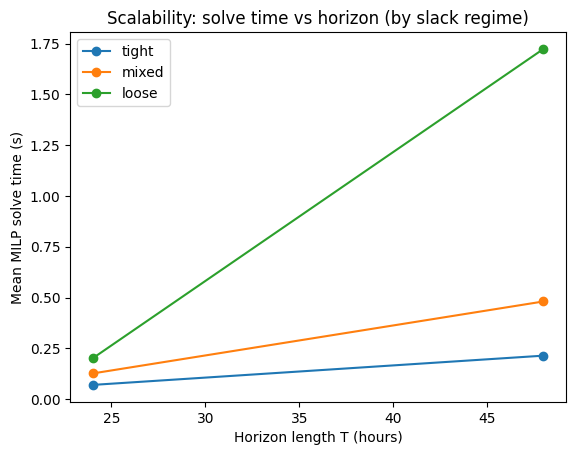


Infeasible rate (rows=horizon/slack, cols=base_rate):


base_rate                   0.4  1.2
horizon_hours slack_regime          
24            loose         0.0  0.0
              mixed         0.0  0.0
              tight         0.0  0.0
48            loose         0.0  0.0
              mixed         0.0  0.0
              tight         0.0  0.0

In [27]:
# @title 6. BENCHMARK: MILP SCALABILITY (solve time vs |J| and T)
# This cell runs a controlled benchmark on ONE region/window to quantify:
# - solve_time_s growth with number of jobs and horizon length
# - infeasibility rate as scaling increases
# Output: CSV + quick plots you can include in your report

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Benchmark configuration
# -------------------------
BENCH_REGION = REGIONS[0]          # e.g., "PJME" (change if you want)
BENCH_AI_FRAC = AI_LOAD_LEVELS[0]  # e.g., 0.10
BENCH_TRIALS = 5                 # keep modest; benchmarks can be slow
BENCH_HEATWAVE = False
BENCH_W_WEIGHT = 0.05
BENCH_IMPORT_FRAC = 0.10          # import limit as congestion proxy
BENCH_INCLUDE_THERMAL = True

# Scaling axes
#HORIZONS_TO_TEST = [24, 48, 72]               # try 96 if runtime is OK
HORIZONS_TO_TEST = [24, 48]               # try 96 if runtime is OK
#BASE_RATES_TO_TEST = [0.4, 0.8, 1.2, 1.6]     # increases expected #jobs
BASE_RATES_TO_TEST = [0.4, 1.2]     # increases expected #jobs
SLACK_REGIMES = ["tight", "mixed", "loose"]   # stress-test feasibility
#SLACK_REGIMES = ["tight", "mixed"]   # stress-test feasibility

# Optional: keep consistent peak clustering
PEAK_AMP = 1.5
PEAK_SIGMA = 8

# Save path
bench_outfile = os.path.join(BASE_DIR, "milp_scalability_benchmark.csv")

# -------------------------
# Run benchmark
# -------------------------
bench_rows = []

print(f"\n=== RUNNING BENCHMARK on region={BENCH_REGION} ai_frac={BENCH_AI_FRAC} ===")

# Load full data once
load_df_full = load_ba_load(BENCH_REGION)
water_df_full = load_water_intensity(BENCH_REGION)

for H in HORIZONS_TO_TEST:
    print(f"\n--- Horizon {H}h ---")

    # Build a quality-gated stressed window for this horizon
    window = build_stressed_window(load_df_full, water_df_full, H)

    L_base = window["L_base_MW"].values
    w_vec  = window["water_m3_per_mwh"].values
    T = len(L_base)
    L_max = float(np.max(L_base))
    t_peak = int(np.argmax(1.15 * L_base))

    import_limit_MW = BENCH_IMPORT_FRAC * L_max

    for base_rate in BASE_RATES_TO_TEST:
        for slack_regime in SLACK_REGIMES:
            infeasible_count = 0

            for trial in range(BENCH_TRIALS):
                rng = np.random.default_rng(trial)

                # Build one workload
                L_online = build_online_ai_load(window, L_max, BENCH_AI_FRAC, rng)
                jobs = generate_jobs_stochastic(
                    T, t_peak, L_max, rng,
                    base_rate=base_rate,
                    peak_amp=PEAK_AMP,
                    peak_sigma=PEAK_SIGMA,
                    slack_regime=slack_regime
                )

                # Ambient temp profile
                Tamb = build_ambient_temperature(window.index, rng, heatwave=BENCH_HEATWAVE)

                # Solve
                sol = solve_milp(
                    L_base, L_online, jobs, w_vec,
                    water_weight=BENCH_W_WEIGHT,
                    Tamb=Tamb,
                    include_thermal=BENCH_INCLUDE_THERMAL,
                    import_limit_MW=import_limit_MW
                )

                status = sol.get("status", "Infeasible")
                if status != "Optimal":
                    infeasible_count += 1

                bench_rows.append({
                    "region": BENCH_REGION,
                    "horizon_hours": int(H),
                    "trial": int(trial),
                    "ai_fraction": float(BENCH_AI_FRAC),
                    "base_rate": float(base_rate),
                    "slack_regime": slack_regime,
                    "include_thermal": int(BENCH_INCLUDE_THERMAL),
                    "heatwave": int(BENCH_HEATWAVE),
                    "water_weight": float(BENCH_W_WEIGHT),
                    "import_frac": float(BENCH_IMPORT_FRAC),
                    "import_limit_MW": float(import_limit_MW),

                    "status": status,
                    "n_jobs": int(sol.get("n_jobs", len(jobs))),
                    "T": int(sol.get("T", T)),
                    "n_vars": int(sol.get("n_vars", 0)),
                    "n_cons": int(sol.get("n_cons", 0)),
                    "solve_time_s": float(sol.get("solve_time_s", 0.0)),

                    # Optional diagnostics if thermal
                    "temp_violation_sum": float(sol.get("temp_violation_sum", 0.0)),
                    "temp_violation_max": float(sol.get("temp_violation_max", 0.0)),
                })

            print(f"base_rate={base_rate:.2f}, slack={slack_regime:5s} "
                  f"infeasible={infeasible_count}/{BENCH_TRIALS}")

bench_df = pd.DataFrame(bench_rows)
bench_df.to_csv(bench_outfile, index=False)
print(f"\nBenchmark saved to: {bench_outfile}")

# -------------------------
# Summaries for the report
# -------------------------
# Use only optimal solves for timing curves
opt_df = bench_df[bench_df["status"] == "Optimal"].copy()

# Aggregate performance
perf = (bench_df
        .groupby(["horizon_hours","base_rate","slack_regime"], as_index=False)
        .agg(
            trials=("status","count"),
            infeasible=("status", lambda s: int((s != "Optimal").sum())),
            infeasible_rate=("status", lambda s: float((s != "Optimal").mean())),
            n_jobs_mean=("n_jobs","mean"),
            n_vars_mean=("n_vars","mean"),
            n_cons_mean=("n_cons","mean"),
            solve_time_mean=("solve_time_s","mean"),
            solve_time_p95=("solve_time_s", lambda x: float(np.percentile(x, 95))),
            solve_time_max=("solve_time_s","max"),
        ))

perf_outfile = os.path.join(BASE_DIR, "milp_scalability_benchmark_summary.csv")
perf.to_csv(perf_outfile, index=False)
print(f"Benchmark summary saved to: {perf_outfile}")

display(perf.sort_values("solve_time_mean", ascending=False).head(12))

# -------------------------
# Plots (simple, no custom colors)
# -------------------------
# 1) Solve time vs number of jobs (scatter)
plt.figure()
plt.scatter(opt_df["n_jobs"], opt_df["solve_time_s"])
plt.xlabel("Number of jobs |J|")
plt.ylabel("MILP solve time (s)")
plt.title("Scalability: solve time vs number of jobs")
plt.show()

# 2) Solve time vs horizon, grouped by slack regime (lines of means)
plt.figure()
for slack in SLACK_REGIMES:
    sub = perf[perf["slack_regime"] == slack].sort_values("horizon_hours")
    # Plot mean solve time (averaged over base_rate and trials) per horizon by taking mean across base_rate
    horizon_mean = sub.groupby("horizon_hours", as_index=False)["solve_time_mean"].mean()
    plt.plot(horizon_mean["horizon_hours"], horizon_mean["solve_time_mean"], marker="o", label=slack)
plt.xlabel("Horizon length T (hours)")
plt.ylabel("Mean MILP solve time (s)")
plt.title("Scalability: solve time vs horizon (by slack regime)")
plt.legend()
plt.show()

# 3) Infeasible rate heat-style table (printed)
pivot = perf.pivot_table(index=["horizon_hours","slack_regime"], columns="base_rate", values="infeasible_rate")
print("\nInfeasible rate (rows=horizon/slack, cols=base_rate):")
display(pivot)


# Charts

In [42]:
# @title Charts A) Load results + traces (new schema)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

res_path = os.path.join(BASE_DIR, RESULTS_FILE)
trace_path = os.path.join(BASE_DIR, "full_simulation_traces.csv")

res_df = pd.read_csv(res_path)
print("Loaded:", res_path, "rows=", len(res_df))

trace_df = None
if os.path.exists(trace_path):
    trace_df = pd.read_csv(trace_path)
    print("Loaded:", trace_path, "rows=", len(trace_df))
else:
    print("Trace file not found:", trace_path)

# Derive optimized C_peak (since results store avoided + baseline)
# C_peak = baseline_capacity - avoided_capacity
res_df["C_peak"] = res_df["baseline_capacity_mw"] - res_df["avoided_capacity_mw"]

# Useful: mark optimal vs infeasible (NaNs in avoided_capacity_mw indicate infeasible)
res_df["is_optimal"] = res_df["avoided_capacity_mw"].notna()

print("\nOptimal rate:", res_df["is_optimal"].mean())
print("Columns:", list(res_df.columns))


Loaded: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/final_scientific_results_optimized.csv rows= 1890
Loaded: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/full_simulation_traces.csv rows= 90720

Optimal rate: 1.0
Columns: ['region', 'ai_fraction', 'trial', 'import_frac', 'heatwave', 'water_weight', 'avoided_capacity_mw', 'water_peak_m3h', 'baseline_capacity_mw', 'baseline_water_m3h', 'water_saved_absolute', 'plants_avoided', 'peak_reduction_pct', 'solve_time_s', 'n_vars', 'n_cons', 'n_jobs', 'T', 'temp_violation_sum', 'temp_violation_max', 'LOLE_base_mean', 'EUE_base_mean', 'LOLE_base_p95', 'EUE_base_p95', 'Wpeak_base_mean_unc', 'Wpeak_base_p95_unc', 'LOLE_opt_mean', 'EUE_opt_mean', 'LOLE_opt_p95', 'EUE_opt_p95', 'Wpeak_opt_mean_unc', 'Wpeak_opt_p95_unc', 'C_peak', 'is_optimal']


In [44]:
# @title Charts B) Helpers (CI summaries + scenario filters)

import numpy as np
import pandas as pd

def mean_ci95(x):
    """Return mean and 95% CI half-width using normal approx."""
    x = pd.Series(x).dropna()
    n = len(x)
    if n <= 1:
        return float(x.mean()) if n == 1 else np.nan, np.nan, n
    m = float(x.mean())
    s = float(x.std(ddof=1))
    ci = 1.96 * s / np.sqrt(n)
    return m, ci, n

def scenario_mask(df, region=None, ai_fraction=None, import_frac=None, heatwave=None):
    m = pd.Series(True, index=df.index)
    if region is not None:
        m &= (df["region"] == region)
    if ai_fraction is not None:
        m &= (df["ai_fraction"] == ai_fraction)
    if import_frac is not None:
        m &= (df["import_frac"] == import_frac)
    if heatwave is not None:
        m &= (df["heatwave"] == int(heatwave))
    return m


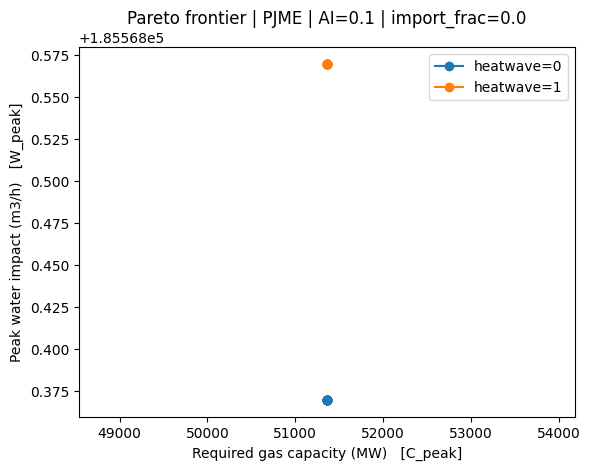

In [46]:
# @title Charts C) Pareto frontier (C_peak vs W_peak) with 95% CI error bars

import matplotlib.pyplot as plt

REGION_TO_PLOT = REGIONS[0]         # change as needed
AI_FRAC_TO_PLOT = AI_LOAD_LEVELS[0] # change as needed
IMPORT_FRAC_TO_PLOT = IMPORT_LIMIT_FRACS[0]  # change as needed

df = res_df[res_df["is_optimal"]].copy()
df = df[scenario_mask(df, region=REGION_TO_PLOT, ai_fraction=AI_FRAC_TO_PLOT, import_frac=IMPORT_FRAC_TO_PLOT)]

if df.empty:
    print("No data for selected scenario. Choose different REGION/AI/import.")
else:
    plt.figure()
    for hw in sorted(df["heatwave"].unique()):
        sub = df[df["heatwave"] == hw]

        # aggregate by water_weight over trials
        rows = []
        for w in sorted(sub["water_weight"].unique()):
            g = sub[sub["water_weight"] == w]
            c_mean, c_ci, n1 = mean_ci95(g["C_peak"])
            w_mean, w_ci, n2 = mean_ci95(g["water_peak_m3h"])
            rows.append((w, c_mean, c_ci, w_mean, w_ci, min(n1, n2)))
        agg = pd.DataFrame(rows, columns=["water_weight","C_peak_mean","C_peak_ci","W_peak_mean","W_peak_ci","n"])

        # plot mean curve
        plt.plot(agg["C_peak_mean"], agg["W_peak_mean"], marker="o", label=f"heatwave={int(hw)}")

        # error bars (x and y)
        plt.errorbar(
            agg["C_peak_mean"], agg["W_peak_mean"],
            xerr=agg["C_peak_ci"], yerr=agg["W_peak_ci"],
            fmt="none", capsize=2
        )

    plt.xlabel("Required gas capacity (MW)   [C_peak]")
    plt.ylabel("Peak water impact (m3/h)   [W_peak]")
    plt.title(f"Pareto frontier | {REGION_TO_PLOT} | AI={AI_FRAC_TO_PLOT} | import_frac={IMPORT_FRAC_TO_PLOT}")
    plt.legend()
    plt.show()


/tmp/ipython-input-1812758683.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[f"{w:.2f}" for w in W_WEIGHTS_TO_SHOW], showfliers=False)


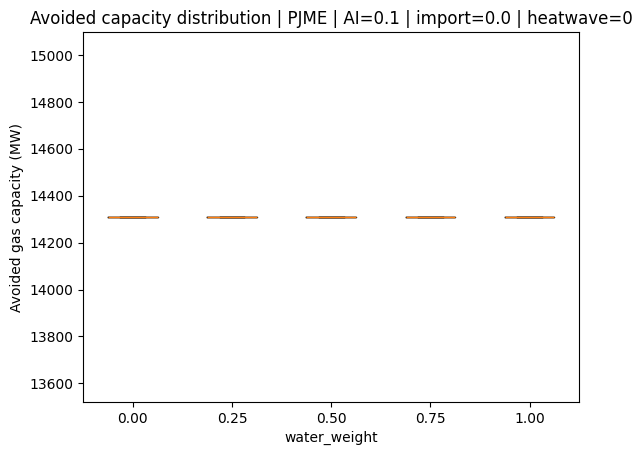

/tmp/ipython-input-1812758683.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[f"{w:.2f}" for w in W_WEIGHTS_TO_SHOW], showfliers=False)


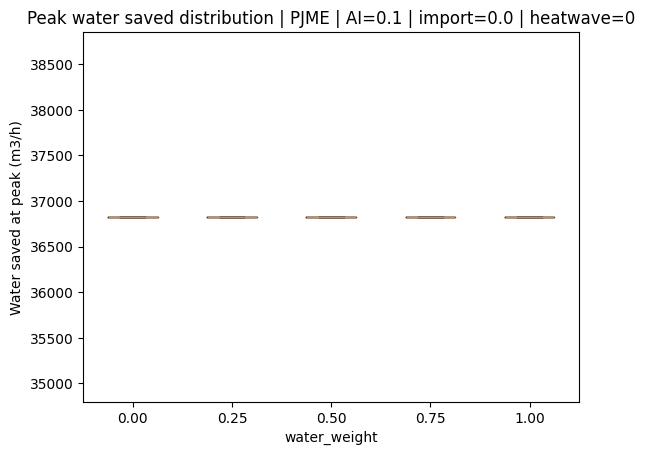

In [47]:
# @title Charts D) Boxplots (variance across trials) for avoided MW and water saved

import matplotlib.pyplot as plt

REGION_TO_PLOT = REGIONS[0]
AI_FRAC_TO_PLOT = AI_LOAD_LEVELS[0]
IMPORT_FRAC_TO_PLOT = IMPORT_LIMIT_FRACS[0]
HEATWAVE_TO_PLOT = 0
W_WEIGHTS_TO_SHOW = sorted(list(set(PARETO_WEIGHTS)))[::5]  # show every 5th weight to reduce clutter

df = res_df[res_df["is_optimal"]].copy()
df = df[scenario_mask(df, region=REGION_TO_PLOT, ai_fraction=AI_FRAC_TO_PLOT, import_frac=IMPORT_FRAC_TO_PLOT, heatwave=HEATWAVE_TO_PLOT)]
df = df[df["water_weight"].isin(W_WEIGHTS_TO_SHOW)]

if df.empty:
    print("No data for selected filters.")
else:
    # Avoided capacity boxplots
    plt.figure()
    data = [df[df["water_weight"]==w]["avoided_capacity_mw"].dropna().values for w in W_WEIGHTS_TO_SHOW]
    plt.boxplot(data, labels=[f"{w:.2f}" for w in W_WEIGHTS_TO_SHOW], showfliers=False)
    plt.xlabel("water_weight")
    plt.ylabel("Avoided gas capacity (MW)")
    plt.title(f"Avoided capacity distribution | {REGION_TO_PLOT} | AI={AI_FRAC_TO_PLOT} | import={IMPORT_FRAC_TO_PLOT} | heatwave={HEATWAVE_TO_PLOT}")
    plt.show()

    # Water saved boxplots
    plt.figure()
    data = [df[df["water_weight"]==w]["water_saved_absolute"].dropna().values for w in W_WEIGHTS_TO_SHOW]
    plt.boxplot(data, labels=[f"{w:.2f}" for w in W_WEIGHTS_TO_SHOW], showfliers=False)
    plt.xlabel("water_weight")
    plt.ylabel("Water saved at peak (m3/h)")
    plt.title(f"Peak water saved distribution | {REGION_TO_PLOT} | AI={AI_FRAC_TO_PLOT} | import={IMPORT_FRAC_TO_PLOT} | heatwave={HEATWAVE_TO_PLOT}")
    plt.show()


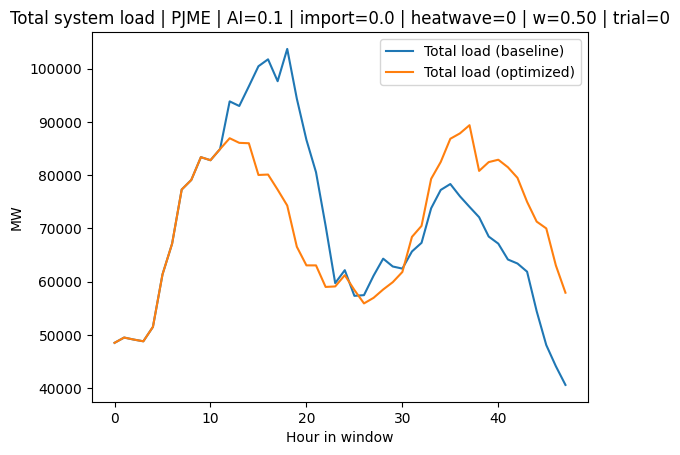

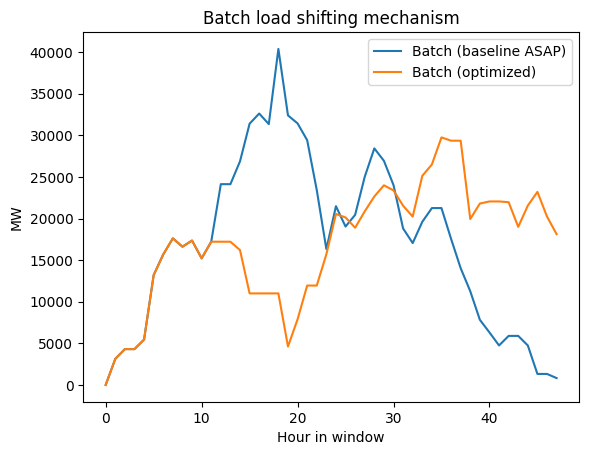

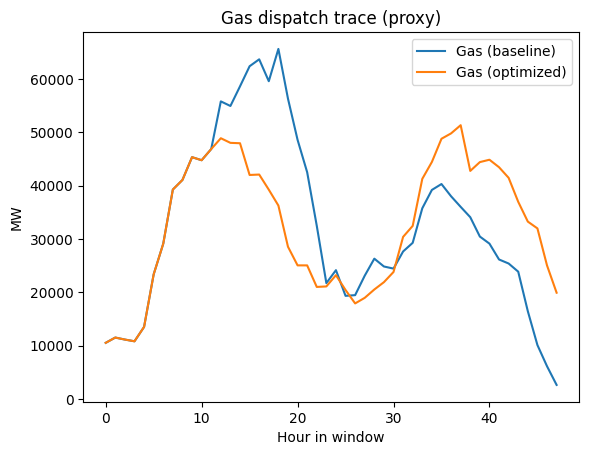

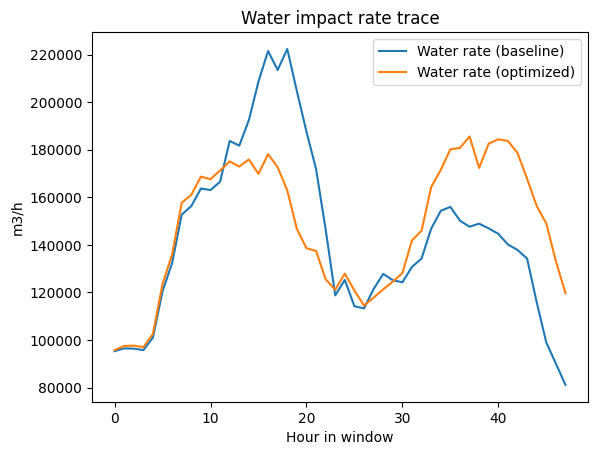

In [48]:
# @title Charts E) Mechanism time-series (base vs optimized) for one scenario

import matplotlib.pyplot as plt
import numpy as np

assert trace_df is not None, "Trace file not loaded. Make sure full_simulation_traces.csv exists."

REGION = REGIONS[0]
AI_FRAC = AI_LOAD_LEVELS[0]
IMPORT_FRAC = IMPORT_LIMIT_FRACS[0]
HEATWAVE = 0
W_WEIGHT = PARETO_WEIGHTS[len(PARETO_WEIGHTS)//2]  # middle weight

# Option A: choose explicit trial
TRIAL_TO_PLOT = None  # set like 0, 1, 2... or leave None for auto median

# Find candidate trials from summary table (optimal only)
subR = res_df[res_df["is_optimal"]].copy()
subR = subR[
    (subR["region"]==REGION) &
    (subR["ai_fraction"]==AI_FRAC) &
    (subR["import_frac"]==IMPORT_FRAC) &
    (subR["heatwave"]==int(HEATWAVE)) &
    (subR["water_weight"]==float(W_WEIGHT))
]
if subR.empty:
    print("No optimal runs for this scenario; choose different settings.")
else:
    if TRIAL_TO_PLOT is None:
        # pick trial with median avoided_capacity
        med = subR["avoided_capacity_mw"].median()
        TRIAL_TO_PLOT = int((subR["avoided_capacity_mw"] - med).abs().idxmin())
        TRIAL_TO_PLOT = int(subR.loc[TRIAL_TO_PLOT, "trial"])

    subT = trace_df[
        (trace_df["region"]==REGION) &
        (trace_df["ai_fraction"]==AI_FRAC) &
        (trace_df["import_frac"]==IMPORT_FRAC) &
        (trace_df["heatwave"]==int(HEATWAVE)) &
        (trace_df["water_weight"]==float(W_WEIGHT)) &
        (trace_df["trial"]==int(TRIAL_TO_PLOT))
    ].sort_values("hour")

    if subT.empty:
        print("No trace rows found for the chosen trial.")
    else:
        h = subT["hour"].values

        # 1) Total load base vs opt
        plt.figure()
        plt.plot(h, subT["L_total_base"].values, label="Total load (baseline)")
        plt.plot(h, subT["L_total_opt"].values, label="Total load (optimized)")
        plt.xlabel("Hour in window")
        plt.ylabel("MW")
        plt.title(f"Total system load | {REGION} | AI={AI_FRAC} | import={IMPORT_FRAC} | heatwave={HEATWAVE} | w={W_WEIGHT:.2f} | trial={TRIAL_TO_PLOT}")
        plt.legend()
        plt.show()

        # 2) Batch load shifted
        plt.figure()
        plt.plot(h, subT["L_batch_base"].values, label="Batch (baseline ASAP)")
        plt.plot(h, subT["L_batch_opt"].values, label="Batch (optimized)")
        plt.xlabel("Hour in window")
        plt.ylabel("MW")
        plt.title("Batch load shifting mechanism")
        plt.legend()
        plt.show()

        # 3) Gas dispatch trace base vs opt
        plt.figure()
        plt.plot(h, subT["g_gas_base"].values, label="Gas (baseline)")
        plt.plot(h, subT["g_gas_opt"].values, label="Gas (optimized)")
        plt.xlabel("Hour in window")
        plt.ylabel("MW")
        plt.title("Gas dispatch trace (proxy)")
        plt.legend()
        plt.show()

        # 4) Water rate base vs opt
        plt.figure()
        plt.plot(h, subT["w_rate_base"].values, label="Water rate (baseline)")
        plt.plot(h, subT["w_rate_opt"].values, label="Water rate (optimized)")
        plt.xlabel("Hour in window")
        plt.ylabel("m3/h")
        plt.title("Water impact rate trace")
        plt.legend()
        plt.show()


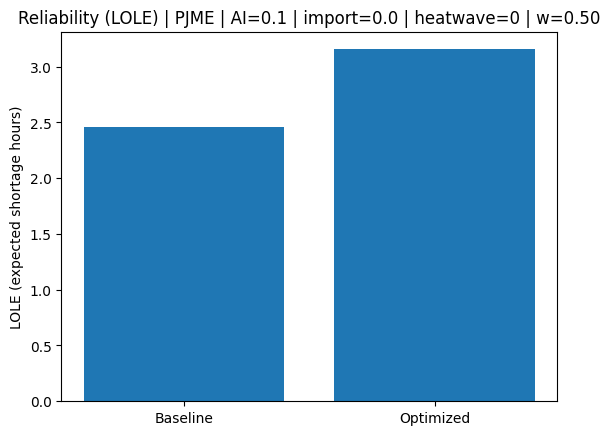

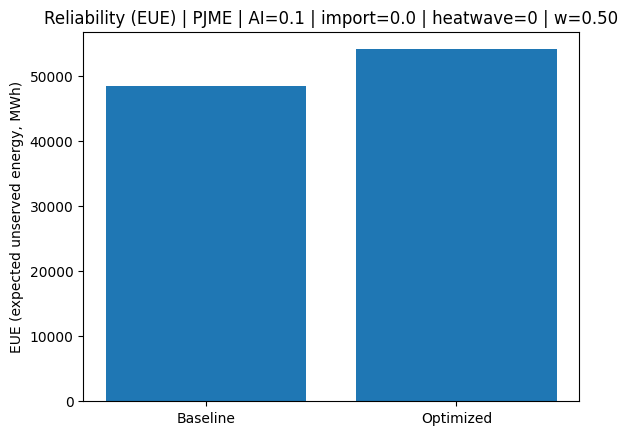

In [49]:
# @title Charts F) Reliability (LOLE/EUE) baseline vs optimized with 95% CI

import matplotlib.pyplot as plt

REGION_TO_PLOT = REGIONS[0]
AI_FRAC_TO_PLOT = AI_LOAD_LEVELS[0]
IMPORT_FRAC_TO_PLOT = IMPORT_LIMIT_FRACS[0]
HEATWAVE_TO_PLOT = 0
W_WEIGHT_TO_PLOT = PARETO_WEIGHTS[len(PARETO_WEIGHTS)//2]

df = res_df[res_df["is_optimal"]].copy()
df = df[
    (df["region"]==REGION_TO_PLOT) &
    (df["ai_fraction"]==AI_FRAC_TO_PLOT) &
    (df["import_frac"]==IMPORT_FRAC_TO_PLOT) &
    (df["heatwave"]==int(HEATWAVE_TO_PLOT)) &
    (df["water_weight"]==float(W_WEIGHT_TO_PLOT))
]

if df.empty:
    print("No data for selected scenario.")
else:
    lole_b, lole_b_ci, _ = mean_ci95(df["LOLE_base_mean"])
    lole_o, lole_o_ci, _ = mean_ci95(df["LOLE_opt_mean"])

    eue_b, eue_b_ci, _ = mean_ci95(df["EUE_base_mean"])
    eue_o, eue_o_ci, _ = mean_ci95(df["EUE_opt_mean"])

    # LOLE bar
    plt.figure()
    plt.bar(["Baseline","Optimized"], [lole_b, lole_o], yerr=[lole_b_ci, lole_o_ci], capsize=4)
    plt.ylabel("LOLE (expected shortage hours)")
    plt.title(f"Reliability (LOLE) | {REGION_TO_PLOT} | AI={AI_FRAC_TO_PLOT} | import={IMPORT_FRAC_TO_PLOT} | heatwave={HEATWAVE_TO_PLOT} | w={W_WEIGHT_TO_PLOT:.2f}")
    plt.show()

    # EUE bar
    plt.figure()
    plt.bar(["Baseline","Optimized"], [eue_b, eue_o], yerr=[eue_b_ci, eue_o_ci], capsize=4)
    plt.ylabel("EUE (expected unserved energy, MWh)")
    plt.title(f"Reliability (EUE) | {REGION_TO_PLOT} | AI={AI_FRAC_TO_PLOT} | import={IMPORT_FRAC_TO_PLOT} | heatwave={HEATWAVE_TO_PLOT} | w={W_WEIGHT_TO_PLOT:.2f}")
    plt.show()


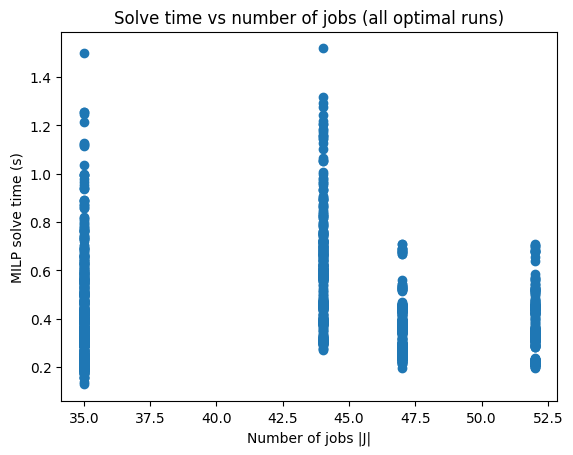

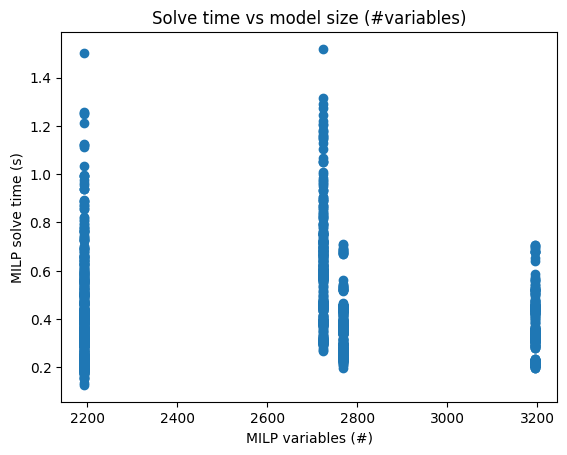

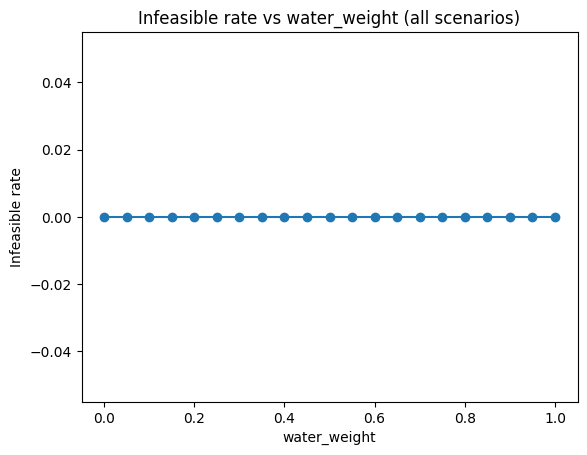

In [50]:
# @title Charts G) Computational details: solve_time vs n_jobs, n_vars; infeasible rate by slack/weight

import matplotlib.pyplot as plt
import numpy as np

# 1) Scatter: solve time vs number of jobs (optimal only)
df = res_df[res_df["is_optimal"]].copy()
if df.empty:
    print("No optimal rows to plot.")
else:
    plt.figure()
    plt.scatter(df["n_jobs"], df["solve_time_s"])
    plt.xlabel("Number of jobs |J|")
    plt.ylabel("MILP solve time (s)")
    plt.title("Solve time vs number of jobs (all optimal runs)")
    plt.show()

    # 2) Scatter: solve time vs number of variables
    plt.figure()
    plt.scatter(df["n_vars"], df["solve_time_s"])
    plt.xlabel("MILP variables (#)")
    plt.ylabel("MILP solve time (s)")
    plt.title("Solve time vs model size (#variables)")
    plt.show()

# 3) Infeasible rate by water_weight (across everything)
rate = res_df.groupby("water_weight")["is_optimal"].mean().reset_index()
plt.figure()
plt.plot(rate["water_weight"], 1.0 - rate["is_optimal"], marker="o")
plt.xlabel("water_weight")
plt.ylabel("Infeasible rate")
plt.title("Infeasible rate vs water_weight (all scenarios)")
plt.show()


In [35]:
# @title Charts H) Export 95% CI summary tables (avoided MW + water saved)

def summarize_ci_table(df, group_cols, metric):
    g = df.groupby(group_cols)[metric]
    out = g.agg(["count","mean","std"]).reset_index()
    out["ci95"] = 1.96 * out["std"] / np.sqrt(out["count"].clip(lower=1))
    return out

opt = res_df[res_df["is_optimal"]].copy()

ci_cap = summarize_ci_table(
    opt,
    ["region","ai_fraction","import_frac","heatwave","water_weight"],
    "avoided_capacity_mw"
)
ci_wat = summarize_ci_table(
    opt,
    ["region","ai_fraction","import_frac","heatwave","water_weight"],
    "water_saved_absolute"
)

cap_path = os.path.join(BASE_DIR, "ci_summary_avoided_capacity.csv")
wat_path = os.path.join(BASE_DIR, "ci_summary_water_saved.csv")

ci_cap.to_csv(cap_path, index=False)
ci_wat.to_csv(wat_path, index=False)

print("Saved:", cap_path)
print("Saved:", wat_path)

display(ci_cap.head(10))


Saved: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/ci_summary_avoided_capacity.csv
Saved: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/ci_summary_water_saved.csv


,region,ai_fraction,import_frac,heatwave,water_weight,count,mean,std,ci95
0,COMED,0.1,0.0,0,0.00,2,772.896126,882.630604,1223.263607
1,COMED,0.1,0.0,0,0.05,2,772.896126,882.630604,1223.263607
2,COMED,0.1,0.0,0,0.10,2,772.896126,882.630604,1223.263607
3,COMED,0.1,0.0,0,0.15,2,772.896126,882.630604,1223.263607
4,COMED,0.1,0.0,0,0.20,2,772.896126,882.630604,1223.263607
5,COMED,0.1,0.0,0,0.25,2,772.896126,882.630604,1223.263607
6,COMED,0.1,0.0,0,0.30,2,772.896126,882.630604,1223.263607
7,COMED,0.1,0.0,0,0.35,2,772.896126,882.630604,1223.263607
8,COMED,0.1,0.0,0,0.40,2,772.896126,882.630604,1223.263607
9,COMED,0.1,0.0,0,0.45,2,772.896126,882.630604,1223.263607




---



In [ ]:
# @title If colab session disconnects, start here to generate graphs.
import pandas as pd
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define your file paths (Update these to match your actual Drive paths)
# For example: '/content/drive/My Drive/Your_Folder/traces.csv'

results_file = "final_scientific_results_optimized.csv"
results_csv_path = os.path.join(BASE_DIR, results_file)
results_df = pd.read_csv(results_csv_path)

trace_file = "full_simulation_traces.csv"
traces_csv_path = os.path.join(BASE_DIR, trace_file)
trace_df = pd.read_csv(traces_csv_path)

# 3. Define the directory where you want to save the plots
if not os.path.exists(BASE_DIR):
    os.makedirs(BASE_DIR)

print(f"Data loaded successfully. Found {len(results_df)} rows and regions: {results_df['region'].unique()}")
print(f"Data loaded successfully. Found {len(trace_df)} rows and regions: {trace_df['region'].unique()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data loaded successfully. Found 15750 rows and regions: ['PJME' 'COMED' 'AEP' 'DAYTON' 'DOM']
Data loaded successfully. Found 756000 rows and regions: ['PJME' 'COMED' 'AEP' 'DAYTON' 'DOM']


# Old Code

In [12]:
# # @title 4. WORKLOAD GENERATION & SOLVER (COMPATIBLE WITH SIMPLIFIED MAIN LOOP)

# import numpy as np
# import pulp

# # --- 1) WORKLOAD GENERATORS ---

# def build_online_ai_load(window_df, L_max, fraction, rng):
#     base = fraction * L_max
#     L_online = np.zeros(len(window_df))
#     for t, ts in enumerate(window_df.index):
#         mult = 1.3 if 9 <= ts.hour <= 21 else 0.4   # diurnal pattern
#         noise = rng.uniform(0.9, 1.1)
#         L_online[t] = base * mult * noise
#     return L_online


# def _sample_slack_hours(rng, regime="mixed"):
#     if regime == "tight":
#         return int(rng.integers(1, 5))        # 1–4h
#     if regime == "medium":
#         return int(rng.integers(6, 13))       # 6–12h
#     if regime == "loose":
#         return int(rng.integers(12, 25))      # 12–24h

#     # mixed: mostly medium, some tight/loose
#     u = rng.random()
#     if u < 0.2:
#         return int(rng.integers(1, 5))
#     if u < 0.85:
#         return int(rng.integers(6, 13))
#     return int(rng.integers(12, 25))


# def generate_jobs_stochastic(T, t_peak, L_max, rng,
#                             base_rate=0.6, peak_amp=1.5, peak_sigma=8,
#                             slack_regime="mixed"):
#     """
#     Stochastic job arrivals:
#       - Poisson arrivals per hour
#       - arrival rate increases around t_peak
#       - job power + duration drawn from size mixture
#       - deadlines determined by sampled slack
#     """
#     jobs = []

#     size_mix = [
#         (0.65, (0.01, 0.03), (1, 4)),    # small
#         (0.28, (0.03, 0.06), (4, 10)),   # medium
#         (0.07, (0.06, 0.10), (10, 18)),  # large
#     ]

#     for t in range(T):
#         lam = base_rate * (1.0 + peak_amp * np.exp(-0.5 * ((t - t_peak) / peak_sigma) ** 2))
#         n_new = rng.poisson(lam)

#         for _ in range(n_new):
#             u = rng.random()
#             cum = 0.0
#             p_frac, dur = None, None
#             for prob, (p_lo, p_hi), (d_lo, d_hi) in size_mix:
#                 cum += prob
#                 if u <= cum:
#                     p_frac = float(rng.uniform(p_lo, p_hi))
#                     dur = int(rng.integers(d_lo, d_hi + 1))
#                     break

#             power = p_frac * L_max
#             slack = _sample_slack_hours(rng, regime=slack_regime)

#             release = t
#             deadline = min(T, release + dur + slack)

#             if deadline - dur < release:
#                 continue

#             jobs.append({
#                 "power": power,
#                 "duration": dur,
#                 "release": release,
#                 "deadline": deadline
#             })

#     return jobs


# def build_ambient_temperature(index, rng, heatwave=False):
#     """
#     Synthetic ambient temp (°C): diurnal sinusoid + noise + optional heatwave shift.
#     """
#     hours = np.array([ts.hour for ts in index], dtype=float)
#     Tamb = 30.0 + 6.0 * np.sin(2 * np.pi * (hours - 15) / 24.0)
#     Tamb = Tamb + rng.normal(0.0, 1.0, size=len(index))
#     if heatwave:
#         Tamb = Tamb + 5.0
#     return Tamb


# # --- 2) SOLVER ---

# def solve_milp(L_base, L_online, jobs, w_vec,
#                alpha=0.3, rho=0.15, water_weight=0.001,
#                Tamb=None, include_thermal=False,
#                tau_hours=6.0, T_init=27.0, T_max=35.0,
#                temp_ref=30.0, wue_base_m3_per_MWh=0.20, wue_temp_slope=0.03,
#                b_temp_per_MW=8e-5,
#                import_limit_MW=0.0):

#     T = len(L_base)
#     L_max = float(np.max(L_base))
#     C_non = np.full(T, (1.0 - alpha) * L_max)

#     prob = pulp.LpProblem("Flex", pulp.LpMinimize)

#     # Decision vars
#     C_gas = pulp.LpVariable("C_gas", lowBound=0)
#     W_peak = pulp.LpVariable("W_peak", lowBound=0)

#     # Thermal vars (optional)
#     if include_thermal:
#         T_dc = pulp.LpVariable.dicts("T_dc", range(T), lowBound=-50)  # no upBound to avoid infeasible
#         T_excess = pulp.LpVariable.dicts("T_excess", range(T), lowBound=0)
#         W_cool = pulp.LpVariable.dicts("W_cool", range(T), lowBound=0)

#         temp_violation = pulp.LpVariable.dicts("temp_violation", range(T), lowBound=0)
#         TEMP_PENALTY = 1e6

#         a = float(np.exp(-1.0 / tau_hours))
#         prob += T_dc[0] == float(T_init)

#     # Job vars
#     x, y = {}, {}
#     for j, job in enumerate(jobs):
#         for t in range(T):
#             x[j, t] = pulp.LpVariable(f"x_{j}_{t}", 0, 1, cat=pulp.LpBinary)  # active
#             y[j, t] = pulp.LpVariable(f"y_{j}_{t}", 0, 1, cat=pulp.LpBinary)  # start

#     # Objective
#     if include_thermal:
#         prob += C_gas + (water_weight * W_peak) + TEMP_PENALTY * pulp.lpSum(temp_violation[t] for t in range(T))
#     else:
#         prob += C_gas + (water_weight * W_peak)

#     # Job constraints: single-start + contiguity
#     for j, job in enumerate(jobs):
#         d = int(job["duration"])
#         r = int(job["release"])
#         D = int(job["deadline"])

#         valid_starts = range(r, D - d + 1)
#         valid_starts_list = list(valid_starts)
#         if len(valid_starts_list) > 0:
#             prob += pulp.lpSum(y[j, t] for t in valid_starts_list) == 1
#         else:
#             # If a job has no feasible start window, declare infeasible quickly
#             return {"status": "Infeasible"}

#         for t in range(T):
#             recent_starts = [y[j, k] for k in range(max(0, t - d + 1), t + 1) if k in valid_starts_list]
#             prob += x[j, t] == pulp.lpSum(recent_starts)

#     # System constraints
#     for t in range(T):
#         L_batch = pulp.lpSum(jobs[j]["power"] * x[j, t] for j in range(len(jobs)))
#         L_total = (1 + rho) * L_base[t] + L_online[t] + L_batch

#         # Adequacy (with import limit proxy)
#         prob += L_total <= C_non[t] + C_gas + import_limit_MW

#         # Water peak
#         if include_thermal:
#             L_dc = L_online[t] + L_batch
#             amb = float(Tamb[t]) if Tamb is not None else 30.0

#             if t < T - 1:
#                 prob += T_dc[t + 1] == a * T_dc[t] + (1 - a) * amb + b_temp_per_MW * L_dc

#             prob += T_dc[t] <= float(T_max) + temp_violation[t]
#             prob += T_excess[t] >= T_dc[t] - float(temp_ref)
#             prob += W_cool[t] == wue_base_m3_per_MWh * L_dc + wue_temp_slope * T_excess[t]

#             prob += W_peak >= (w_vec[t] * L_total) + W_cool[t]
#         else:
#             prob += W_peak >= w_vec[t] * L_total

#     # Solve
#     prob.solve(pulp.PULP_CBC_CMD(msg=False))

#     if pulp.LpStatus[prob.status] != "Optimal":
#         return {"status": "Infeasible"}

#     # Reconstruct traces
#     L_batch_opt = np.zeros(T)
#     for t in range(T):
#         L_batch_opt[t] = sum(jobs[j]["power"] * (pulp.value(x[j, t]) or 0.0) for j in range(len(jobs)))

#     L_total_opt = (1 + rho) * L_base + L_online + L_batch_opt
#     g_gas_opt = np.maximum(0, L_total_opt - (C_non + import_limit_MW))  # consistent with baseline

#     if include_thermal:
#         W_cool_opt = np.array([(pulp.value(W_cool[t]) or 0.0) for t in range(T)], dtype=float)
#         w_rate_opt = (w_vec * L_total_opt) + W_cool_opt
#         tv_sum = float(sum((pulp.value(temp_violation[t]) or 0.0) for t in range(T)))
#         tv_max = float(max((pulp.value(temp_violation[t]) or 0.0) for t in range(T)))
#     else:
#         W_cool_opt = np.zeros(T)
#         w_rate_opt = w_vec * L_total_opt
#         tv_sum, tv_max = 0.0, 0.0

#     return {
#         "status": "Optimal",
#         "C_peak": float(pulp.value(C_gas) or 0.0),
#         "W_peak": float(pulp.value(W_peak) or 0.0),
#         "temp_violation_sum": tv_sum,
#         "temp_violation_max": tv_max,
#         "L_batch": L_batch_opt,
#         "L_total": L_total_opt,
#         "g_gas": g_gas_opt,
#         "w_rate": w_rate_opt,
#         "W_cool": W_cool_opt,
#     }


# # --- 3) PROBABILISTIC ADEQUACY METRICS (LOLE/EUE) ---

# def adequacy_risk_metrics(L_total, C_non, C_gas_value, rng,
#                          sigma_load=0.03, forced_outage_rate=0.03, n_scen=200):
#     """
#     LOLE-like: expected hours with any shortfall
#     EUE: expected unserved energy (MWh over horizon since hourly)
#     Includes load forecast error + forced outage of gas capacity.
#     """
#     T = len(L_total)
#     lole_hours, eue_mwh = [], []

#     for _ in range(n_scen):
#         eps = rng.normal(0.0, sigma_load, size=T)
#         Ls = L_total * (1.0 + eps)

#         gas_available = C_gas_value * (1.0 - (rng.random(T) < forced_outage_rate).astype(float))
#         shortfall = np.maximum(0.0, Ls - (C_non + gas_available))

#         lole_hours.append(np.sum(shortfall > 0))
#         eue_mwh.append(np.sum(shortfall))

#     return {
#         "LOLE_hours_mean": float(np.mean(lole_hours)),
#         "EUE_MWh_mean": float(np.mean(eue_mwh)),
#         "LOLE_hours_p95": float(np.percentile(lole_hours, 95)),
#         "EUE_MWh_p95": float(np.percentile(eue_mwh, 95)),
#     }


In [ ]:
# # @title 5. MAIN EXECUTION LOOP (SIMPLIFIED + IMPORT LIMIT + HEATWAVE + LOLE/EUE)
# # ==========================================
# # 5. MAIN EXECUTION LOOP
# # ==========================================

# from itertools import product

# print("\n=== STARTING MULTI-REGION STUDY ===")
# results = []
# all_traces = []  # Storage for full time-series data

# # Scenario grid (flat loop later)
# scenario_grid = list(product(IMPORT_LIMIT_FRACS, HEATWAVE_SCENARIOS, PARETO_WEIGHTS))

# for region in REGIONS:
#     print(f"\nProcessing Region: {region}...")
#     try:
#         # 1) Load Data
#         load_df = load_ba_load(region)
#         water_df = load_water_intensity(region)

#         # 2) Build Window
#         window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
#         L_base = window["L_base_MW"].values
#         w_vec = window["water_m3_per_mwh"].values
#         T = len(L_base)
#         L_max = float(np.max(L_base))

#         # Identify Peak Index for job clustering
#         base_total = 1.15 * L_base
#         t_peak = int(np.argmax(base_total))

#         # 3) Run Scenarios (simplified nesting)
#         for ai_frac in AI_LOAD_LEVELS:
#             print(f"   -> AI Level: {ai_frac:.2f}")

#             for trial in range(N_TRIALS):
#                 rng = np.random.default_rng(trial)

#                 # --- Build ONE workload per trial (reused across all weights/import/heatwave) ---
#                 L_online = build_online_ai_load(window, L_max, ai_frac, rng)
#                 jobs = generate_jobs_stochastic(T, t_peak, L_max, rng, slack_regime="mixed")

#                 # --- Baseline (compute ONCE per trial) ---
#                 L_naive_batch = np.zeros(T)
#                 for job in jobs:
#                     start_t = job["release"]
#                     end_t = min(start_t + job["duration"], T)
#                     L_naive_batch[start_t:end_t] += job["power"]

#                 L_total_naive = (1.15 * L_base) + L_online + L_naive_batch

#                 # Non-gas capacity (same as solver's alpha=0.3 default)
#                 C_non_gas = (1.0 - 0.3) * L_max

#                 # Baseline water peak does NOT depend on import limit
#                 w_base_trace = w_vec * L_total_naive
#                 w_base = float(np.max(w_base_trace))

#                 # Precompute ambient temperatures for both heatwave modes
#                 Tamb_by_hw = {
#                     hw: build_ambient_temperature(window.index, rng, heatwave=hw)
#                     for hw in HEATWAVE_SCENARIOS
#                 }

#                 # --- Flat scenario loop ---
#                 for import_frac, heatwave, w_weight in scenario_grid:
#                     import_limit_MW = import_frac * L_max

#                     # Baseline gas peak DOES depend on import limit (congestion proxy)
#                     g_base_trace = np.maximum(0, L_total_naive - (C_non_gas + import_limit_MW))
#                     c_base = float(np.max(g_base_trace))

#                     # Solve optimized schedule
#                     sol = solve_milp(
#                         L_base, L_online, jobs, w_vec,
#                         water_weight=w_weight,
#                         Tamb=Tamb_by_hw[heatwave], include_thermal=True,
#                         import_limit_MW=import_limit_MW
#                     )

#                     if sol["status"] == "Optimal":
#                         avoided_mw = c_base - sol["C_peak"]
#                         water_saved_abs = w_base - sol["W_peak"]

#                         # Probabilistic adequacy evaluation (LOLE/EUE)
#                         risk_base = adequacy_risk_metrics(L_total_naive, C_non_gas*np.ones(T), c_base, rng)
#                         risk_opt  = adequacy_risk_metrics(sol["L_total"], C_non_gas*np.ones(T), sol["C_peak"], rng)

#                         results.append({
#                             "region": region,
#                             "ai_fraction": ai_frac,
#                             "trial": trial,
#                             "import_frac": float(import_frac),
#                             "heatwave": int(heatwave),
#                             "water_weight": float(w_weight),

#                             "avoided_capacity_mw": float(avoided_mw),
#                             "water_peak_m3h": float(sol["W_peak"]),
#                             "baseline_capacity_mw": float(c_base),
#                             "baseline_water_m3h": float(w_base),
#                             "water_saved_absolute": float(water_saved_abs),

#                             "plants_avoided": float(avoided_mw / PLANT_SIZE_MW),
#                             "peak_reduction_pct": float((avoided_mw / c_base * 100) if c_base > 0 else 0),

#                             "LOLE_base_mean": risk_base["LOLE_hours_mean"],
#                             "EUE_base_mean": risk_base["EUE_MWh_mean"],
#                             "LOLE_opt_mean":  risk_opt["LOLE_hours_mean"],
#                             "EUE_opt_mean":   risk_opt["EUE_MWh_mean"],
#                             "LOLE_base_p95":  risk_base["LOLE_hours_p95"],
#                             "EUE_base_p95":   risk_base["EUE_MWh_p95"],
#                             "LOLE_opt_p95":   risk_opt["LOLE_hours_p95"],
#                             "EUE_opt_p95":    risk_opt["EUE_MWh_p95"],
#                         })

#                         # Full traces
#                         for t in range(T):
#                             all_traces.append({
#                                 "region": region,
#                                 "ai_fraction": ai_frac,
#                                 "trial": trial,
#                                 "import_frac": float(import_frac),
#                                 "heatwave": int(heatwave),
#                                 "water_weight": float(w_weight),
#                                 "hour": int(t),

#                                 "L_grid": float(L_base[t]),
#                                 "L_online": float(L_online[t]),
#                                 "water_intensity": float(w_vec[t]),

#                                 "L_batch_base": float(L_naive_batch[t]),
#                                 "L_total_base": float(L_total_naive[t]),
#                                 "g_gas_base": float(g_base_trace[t]),
#                                 "w_rate_base": float(w_base_trace[t]),

#                                 "L_batch_opt": float(sol["L_batch"][t]),
#                                 "L_total_opt": float(sol["L_total"][t]),
#                                 "g_gas_opt": float(sol["g_gas"][t]),
#                                 "w_rate_opt": float(sol["w_rate"][t]),
#                             })
#                     else:
#                         print(f"Warning: {sol['status']} for {region} AI={ai_frac} trial={trial} "
#                               f"import={import_frac:.2f} heatwave={heatwave} w={w_weight:.3f}")

#     except Exception as e:
#         print(f"!!! Error processing {region}: {e}")

# # ==========================================
# # SAVE RESULTS
# # ==========================================
# res_df = pd.DataFrame(results)
# res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
# print(f"\nStudy Complete. Summary results saved to {RESULTS_FILE}")

# if all_traces:
#     trace_file = "full_simulation_traces.csv"
#     trace_df = pd.DataFrame(all_traces)
#     trace_df.to_csv(os.path.join(BASE_DIR, trace_file), index=False)
#     print(f"Full Traces saved to {trace_file} ({len(trace_df)} rows)")


In [11]:
# # @title 3. DATA LOADERS
# # ==========================================
# # 3. DATA LOADERS
# # ==========================================

# def load_ba_load(region: str):
#     """Loads Grid Load, handles duplicates, standardizes columns."""
#     print(f"   -> Loading Grid Load for {region}...")
#     fname = f"{region}_hourly.csv"
#     path = os.path.join(HOURLY_LOAD_DIR, fname)

#     if not os.path.exists(path):
#         raise FileNotFoundError(f"File not found: {path}")

#     # Load & Parse
#     df = pd.read_csv(path, parse_dates=["Datetime"])

#     # Rename value column to 'load_MW'
#     mw_col = [c for c in df.columns if c.endswith("_MW")][0]
#     df = df.rename(columns={mw_col: "load_MW"})

#     # Index & De-duplicate (Fixes "cannot reindex" error)
#     df = df.set_index("Datetime").sort_index()
#     df = df.groupby(df.index).mean(numeric_only=True)

#     return df

# def load_water_intensity(region: str):
#     """Loads Water Data, Maps Sub-regions (PJME->PJM), Fixes Text/Numeric Errors."""
#     print(f"   -> Loading Water Intensity for {region}...")

#     # --- SMART MAPPING ---
#     REGION_MAP = {
#         "PJME": "PJM", "PJMW": "PJM", "COMED": "PJM", "DAYTON": "PJM",
#         "AEP": "PJM", "DOM": "PJM", "DUQ": "PJM", "FE": "PJM",
#         "DEOK": "PJM", "NI": "PJM", "PJM": "PJM",
#         "CISO": "CISO", "ERCOT": "ERCO", "SPP": "SWPP"
#     }
#     search_region = REGION_MAP.get(region, region)

#     path = os.path.join(BASE_DIR, "Water_IMPACT-Data_Consumption_2020.csv")
#     if not os.path.exists(path):
#         # Fallback to searching raw folder
#         path = os.path.join(WATER_IMPACT_DIR, "Water_IMPACT-Data_Consumption_2020.csv")

#     df = pd.read_csv(path, parse_dates=["date"])

#     # Filter by Region
#     col = "balancing_authority" if "balancing_authority" in df.columns else "ba_code"
#     df = df[df[col] == search_region].copy()

#     if df.empty:
#         raise ValueError(f"Region '{search_region}' not found in Water Data.")

#     # Index & De-duplicate (Fixes TypeError: string to numeric)
#     df = df.set_index("date").sort_index()
#     df = df.groupby(df.index).mean(numeric_only=True)

#     # Select Consumption Column
#     target = "wci_primary" if "wci_primary" in df.columns else "w_consume_l_per_kwh"
#     df["w_m3_per_MWh"] = pd.to_numeric(df[target], errors="coerce") * DROUGHT_FACTOR

#     # Resample to Hourly & Fill Gaps
#     df_clean = df[["w_m3_per_MWh"]].resample("h").mean()
#     df_clean = df_clean.interpolate(limit=3).ffill().bfill()

#     return df_clean

# def build_stressed_window(load_df, water_df, horizon_hours):
#     """Aligns Historical Peak Load (e.g., 2015) with Water Data (2020)."""
#     print("   -> Extracting Peak Window...")

#     # 1. Find Historical Peak
#     rolling = load_df["load_MW"].rolling(window=24*7, min_periods=24).mean()
#     peak_time = rolling.idxmax()

#     # 2. Extract Window
#     half = timedelta(hours=horizon_hours // 2)
#     start = peak_time - half
#     end = start + timedelta(hours=horizon_hours - 1)

#     # 3. Time Shift Logic (Project to Water Year)
#     target_year = water_df.index.year[0] # Detects 2020

#     # extract slice
#     load_slice = load_df.loc[start:end].copy()

#     # Shift index to target year
#     new_dates = []
#     for d in load_slice.index:
#         try:
#             new_d = d.replace(year=target_year)
#         except ValueError: # Leap year fix
#             new_d = d.replace(year=target_year, month=3, day=1)
#         new_dates.append(new_d)

#     load_slice.index = pd.DatetimeIndex(new_dates)

#     # 4. Merge
#     window_df = pd.DataFrame(index=load_slice.index)
#     window_df["L_base_MW"] = load_slice["load_MW"]
#     window_df["water_m3_per_mwh"] = water_df["w_m3_per_MWh"].reindex(window_df.index)

#     # Fill remaining gaps from reindexing
#     window_df = window_df.interpolate(limit=3).ffill().bfill()

#     return window_df

In [8]:
# # @title 4. WORKLOAD GENERATION & SOLVER
# import numpy as np
# import pulp

# # --- 1. WORKLOAD GENERATORS (Unchanged) ---
# def build_online_ai_load(window_df, L_max, fraction, rng):
#     base = fraction * L_max
#     L_online = np.zeros(len(window_df))
#     for t, ts in enumerate(window_df.index):
#         # Diurnal pattern: Higher during day (9am-9pm)
#         mult = 1.3 if 9 <= ts.hour <= 21 else 0.4
#         noise = rng.uniform(0.9, 1.1)
#         L_online[t] = base * mult * noise
#     return L_online

# # def generate_jobs(T, t_peak, L_max, rng):
# #     # Simplified Job Generator
# #     jobs = []
# #     # Mix of small, medium, large jobs
# #     configs = [("small", 10, 0.02, 4), ("medium", 5, 0.05, 8), ("large", 2, 0.08, 12)]

# #     for name, count, p_frac, d_base in configs:
# #         for _ in range(count):
# #             p = rng.uniform(p_frac*0.8, p_frac*1.2) * L_max
# #             dur = int(rng.integers(d_base-2, d_base+3))
# #             # Release near peak
# #             r_center = max(0, t_peak - 4)
# #             r = int(rng.integers(max(0, r_center-10), min(T, r_center+10)))
# #             deadline = min(T, r + dur + 12) # 12h slack
# #             jobs.append({"power": p, "duration": dur, "release": r, "deadline": deadline})
# #     return jobs



# def _sample_slack_hours(rng, regime="mixed"):
#     # Slack distributions (hours): tight/medium/loose + mixture option
#     if regime == "tight":
#         return int(rng.integers(1, 5))        # 1–4h
#     if regime == "medium":
#         return int(rng.integers(6, 13))       # 6–12h
#     if regime == "loose":
#         return int(rng.integers(12, 25))      # 12–24h

#     # mixed regime (more realistic): mostly medium, some tight/loose
#     u = rng.random()
#     if u < 0.2:
#         return int(rng.integers(1, 5))
#     if u < 0.85:
#         return int(rng.integers(6, 13))
#     return int(rng.integers(12, 25))


# def generate_jobs_stochastic(T, t_peak, L_max, rng,
#                             base_rate=0.6, peak_amp=1.5, peak_sigma=8,
#                             slack_regime="mixed"):
#     """
#     Stochastic job arrivals:
#       - Poisson arrivals each hour
#       - Arrival rate increases around system peak (optional)
#       - Size + duration drawn from distributions
#       - Deadlines derived from sampled slack
#     """
#     jobs = []

#     # size-mixture: (prob, power_frac_range, duration_range)
#     size_mix = [
#         (0.65, (0.01, 0.03), (1, 4)),    # small
#         (0.28, (0.03, 0.06), (4, 10)),   # medium
#         (0.07, (0.06, 0.10), (10, 18)),  # large
#     ]

#     for t in range(T):
#         # time-varying arrival intensity (peak around t_peak)
#         lam = base_rate * (1.0 + peak_amp * np.exp(-0.5 * ((t - t_peak) / peak_sigma) ** 2))
#         n_new = rng.poisson(lam)

#         for _ in range(n_new):
#             # pick job class
#             u = rng.random()
#             cum = 0.0
#             for prob, (p_lo, p_hi), (d_lo, d_hi) in size_mix:
#                 cum += prob
#                 if u <= cum:
#                     p_frac = rng.uniform(p_lo, p_hi)
#                     dur = int(rng.integers(d_lo, d_hi + 1))
#                     break

#             power = p_frac * L_max
#             slack = _sample_slack_hours(rng, regime=slack_regime)

#             release = t
#             deadline = min(T, release + dur + slack)  # ensure feasible window exists

#             # If too tight to schedule, skip (rare but keeps MILP feasible)
#             if deadline - dur < release:
#                 continue

#             jobs.append({
#                 "power": power,
#                 "duration": dur,
#                 "release": release,
#                 "deadline": deadline
#             })

#     return jobs


# def build_ambient_temperature(index, rng, heatwave=False):
#     """
#     Synthetic ambient temp (°C): diurnal sinusoid + noise + optional heatwave shift.
#     """
#     hours = np.array([ts.hour for ts in index], dtype=float)
#     Tamb = 30.0 + 6.0 * np.sin(2 * np.pi * (hours - 15) / 24.0)  # peak mid-afternoon
#     Tamb = Tamb + rng.normal(0.0, 1.0, size=len(index))          # weather noise
#     if heatwave:
#         Tamb = Tamb + 5.0
#     return Tamb



# # --- 2. SOLVER (Enhanced for Pareto & Traces) ---
# # =========================================================
# # CHANGE: Added water_weight parameter for Multi-Objective Analysis
# # =========================================================
# #def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15, water_weight=0.001): # NEW
# def solve_milp(L_base, L_online, jobs, w_vec, alpha=0.3, rho=0.15, water_weight=0.001,
#                Tamb=None, include_thermal=False, tau_hours=6.0, T_init=27.0, T_max=35.0,
#                temp_ref=30.0, wue_base_m3_per_MWh=0.20, wue_temp_slope=0.03, b_temp_per_MW=8e-5,
#                import_limit_MW=0.0):
#     T = len(L_base)
#     L_max = L_base.max()
#     C_non = np.full(T, (1.0 - alpha) * L_max)

#     prob = pulp.LpProblem("Flex", pulp.LpMinimize)

#     # Vars
#     C_gas = pulp.LpVariable("C_gas", 0)
#     W_peak = pulp.LpVariable("W_peak", 0)
#     # Optional thermal/cooling variables (linear)
#     if include_thermal:
#         #T_dc = pulp.LpVariable.dicts("T_dc", range(T), lowBound=-50, upBound=100)
#         T_dc = pulp.LpVariable.dicts("T_dc", range(T), lowBound=-50)
#         T_excess = pulp.LpVariable.dicts("T_excess", range(T), lowBound=0)
#         W_cool = pulp.LpVariable.dicts("W_cool", range(T), lowBound=0)
#         # NEW: allow rare temperature violations to avoid infeasibility
#         temp_violation = pulp.LpVariable.dicts("temp_violation", range(T), lowBound=0)
#         TEMP_PENALTY = 1e6  # huge penalty so solver avoids violating unless necessary

#         a = float(np.exp(-1.0 / tau_hours))  # discrete-time decay factor
#         prob += T_dc[0] == T_init




#     # Job Vars: x[j,t] = 1 if job j is active at time t
#     x = {}
#     y = {} # Start vars

#     for j, job in enumerate(jobs):
#         for t in range(T):
#             x[j,t] = pulp.LpVariable(f"x_{j}_{t}", 0, 1, pulp.LpBinary)
#             y[j,t] = pulp.LpVariable(f"y_{j}_{t}", 0, 1, pulp.LpBinary)

#     # =========================================================
#     # CHANGE: Use dynamic weight for Pareto Frontier exploration
#     # =========================================================
#     # Objective: Minimize Capacity + weighted Water penalty
#     # prob += C_gas + 0.001 * W_peak # OLD
#     # prob += C_gas + (water_weight * W_peak) # NEW
#     if include_thermal:
#         prob += C_gas + (water_weight * W_peak) + TEMP_PENALTY * pulp.lpSum(temp_violation[t] for t in range(T))
#     else:
#         prob += C_gas + (water_weight * W_peak)



#     # Constraints
#     for j, job in enumerate(jobs):
#         d, r, D = job["duration"], job["release"], job["deadline"]

#         # 1. Single Start
#         valid_starts = range(r, D - d + 1)
#         if len(valid_starts) > 0:
#             prob += pulp.lpSum(y[j,t] for t in valid_starts) == 1

#         # 2. Contiguity (x is sum of recent y's)
#         for t in range(T):
#             # Sum of starts in window [t-d+1, t]
#             recent_starts = [y[j,k] for k in range(max(0, t-d+1), t+1) if k in valid_starts]
#             prob += x[j,t] == pulp.lpSum(recent_starts)

#     # System Constraints
#     # for t in range(T):
#     #     L_batch = pulp.lpSum(jobs[j]["power"] * x[j,t] for j in range(len(jobs)))
#     #     L_total = (1+rho)*L_base[t] + L_online[t] + L_batch

#     #     # Adequacy
#     #     prob += L_total <= C_non[t] + C_gas

#     #     # Water Peak
#     #     prob += W_peak >= w_vec[t] * L_total

#     # System Constraints
#     for t in range(T):
#         L_batch = pulp.lpSum(jobs[j]["power"] * x[j,t] for j in range(len(jobs)))
#         L_total = (1+rho)*L_base[t] + L_online[t] + L_batch

#         # Adequacy
#         # prob += L_total <= C_non[t] + C_gas
#         prob += L_total <= C_non[t] + C_gas + import_limit_MW


#         if include_thermal:
#             # Data center IT load drives temperature (online + batch)
#             L_dc = L_online[t] + L_batch

#             # Ambient temp for this hour
#             amb = float(Tamb[t]) if Tamb is not None else 30.0

#             # Thermal dynamics (for t < T-1)
#             if t < T - 1:
#                 prob += T_dc[t+1] == a * T_dc[t] + (1 - a) * amb + b_temp_per_MW * L_dc

#             # Thermal cap
#             # prob += T_dc[t] <= T_max
#             prob += T_dc[t] <= T_max + temp_violation[t]


#             # Excess temperature (linear)
#             prob += T_excess[t] >= T_dc[t] - temp_ref

#             # Cooling water increases with IT energy + temp stress (linear)
#             prob += W_cool[t] == wue_base_m3_per_MWh * L_dc + wue_temp_slope * T_excess[t]

#             # Peak water includes grid water + cooling water
#             prob += W_peak >= (w_vec[t] * L_total) + W_cool[t]
#         else:
#             # Original model
#             prob += W_peak >= w_vec[t] * L_total


# def adequacy_risk_metrics(L_total, C_non, C_gas_value, rng,
#                           sigma_load=0.03, forced_outage_rate=0.03, n_scen=200):
#     """
#     LOLE-like: expected # of hours with any shortfall
#     EUE: expected unserved energy (MWh over horizon since hourly)
#     We include:
#       - load forecast error (multiplicative)
#       - forced outage of added gas capacity (simple Bernoulli each hour)
#     """
#     T = len(L_total)
#     lole_hours = []
#     eue_mwh = []

#     for _ in range(n_scen):
#         eps = rng.normal(0.0, sigma_load, size=T)
#         Ls = L_total * (1.0 + eps)

#         # gas capacity available each hour (can be unavailable due to outage)
#         gas_available = C_gas_value * (1.0 - (rng.random(T) < forced_outage_rate).astype(float))

#         shortfall = np.maximum(0.0, Ls - (C_non + gas_available))
#         lole_hours.append(np.sum(shortfall > 0))
#         eue_mwh.append(np.sum(shortfall))

#     return {
#         "LOLE_hours_mean": float(np.mean(lole_hours)),
#         "EUE_MWh_mean": float(np.mean(eue_mwh)),
#         "LOLE_hours_p95": float(np.percentile(lole_hours, 95)),
#         "EUE_MWh_p95": float(np.percentile(eue_mwh, 95)),
#     }




#     # Solve
#     prob.solve(pulp.PULP_CBC_CMD(msg=False))

#     # Returns Full Traces (Dictionary)
#     if prob.status == 1: # Optimal
#         # 1. Reconstruct the Hourly Optimized Batch Load
#         L_batch_opt = np.zeros(T)
#         for t in range(T):
#             # Sum power of all active jobs at time t
#             L_batch_opt[t] = sum(jobs[j]["power"] * pulp.value(x[j,t]) for j in range(len(jobs)))

#         # 2. Recompute System Traces
#         L_total_opt = (1+rho)*L_base + L_online + L_batch_opt
#         g_gas_opt = np.maximum(0, L_total_opt - C_non)
#         w_rate_opt = w_vec * L_total_opt

#         return {
#             "status": "Optimal",
#             "C_peak": pulp.value(C_gas),
#             "W_peak": pulp.value(W_peak),
#             # NEW: thermal feasibility diagnostics
#             "temp_violation_sum": float(sum(pulp.value(temp_violation[t]) for t in range(T))) if include_thermal else 0.0,
#             #"temp_violation_max": float(max(pulp.value(temp_violation[t]) for t in range(T))) if include_thermal else 0.0,
#             "temp_violation_max": float(max((pulp.value(temp_violation[t]) or 0.0) for t in range(T))) if include_thermal else 0.0,
#             "L_batch": L_batch_opt,
#             "L_total": L_total_opt,
#             "g_gas": g_gas_opt,
#             "w_rate": w_rate_opt
#         }
#     else:
#         return {"status": "Infeasible"}

In [9]:
# # @title 5. MAIN EXECUTION LOOP
# # ==========================================
# # 5. MAIN EXECUTION LOOP
# # ==========================================
# print("\n=== STARTING MULTI-REGION STUDY ===")
# results = []
# all_traces = [] # Storage for full time-series data

# for region in REGIONS:
#     print(f"\nProcessing Region: {region}...")
#     try:
#         # 1. Load Data
#         load_df = load_ba_load(region)
#         water_df = load_water_intensity(region)

#         # 2. Build Window
#         window = build_stressed_window(load_df, water_df, HORIZON_HOURS)
#         L_base = window["L_base_MW"].values
#         w_vec = window["water_m3_per_mwh"].values
#         T = len(L_base)
#         L_max = L_base.max()

#         # Identify Peak Index for job clustering
#         base_total = (1 + 0.15) * L_base
#         t_peak = np.argmax(base_total)

#         # 3. Run Scenarios
#         for ai_frac in AI_LOAD_LEVELS:
#             print(f"   -> AI Level: {ai_frac:.2f}")

#             # =========================================================
#             # NEW: Pareto Frontier Loop (Gas vs. Water Trade-offs)
#             # =========================================================
#             for w_weight in PARETO_WEIGHTS:
#                 # Optional: print(f"      -> Weight: {w_weight}")

#                 for trial in range(N_TRIALS):
#                     rng = np.random.default_rng(trial)

#                     # Create Workload
#                     L_online = build_online_ai_load(window, L_max, ai_frac, rng)
#                     # jobs = generate_jobs(T, t_peak, L_max, rng)
#                     jobs = generate_jobs_stochastic(T, t_peak, L_max, rng, slack_regime="mixed")


#             for w_weight in PARETO_WEIGHTS:
#                 # NEW: heatwave scenario sweep
#                 for heatwave in HEATWAVE_SCENARIOS:
#                     for trial in range(N_TRIALS):
#                         rng = np.random.default_rng(trial)

#                         # NEW: build ambient temperature profile (used only if include_thermal=True)
#                         Tamb = build_ambient_temperature(window.index, rng, heatwave=heatwave)

#                         # Create Workload
#                         L_online = build_online_ai_load(window, L_max, ai_frac, rng)
#                         jobs = generate_jobs_stochastic(T, t_peak, L_max, rng, slack_regime="mixed")


#                     # =========================================================
#                     # A. COMPUTE TRUE BASELINE (Naive)
#                     # =========================================================
#                     # 1. Reconstruct Naive Batch Profile (Jobs run ASAP at release)
#                     L_naive_batch = np.zeros(T)
#                     for job in jobs:
#                         start_t = job["release"]
#                         end_t = min(start_t + job["duration"], T)
#                         L_naive_batch[start_t : end_t] += job["power"]

#                     # 2. Calculate Total System Load (Naive)
#                     L_total_naive = (1.15 * L_base) + L_online + L_naive_batch

#                     # 3. Calculate "Before" Metrics
#                     C_non_gas = (1.0 - 0.3) * L_max
#                     # Gas Dispatch Trace (Naive)
#                     g_base_trace = np.maximum(0, L_total_naive - C_non_gas)
#                     c_base = max(0, np.max(g_base_trace))

#                     # Water Peak (Naive)
#                     w_base_trace = w_vec * L_total_naive
#                     w_base = np.max(w_base_trace)

#                     # Tamb = build_ambient_temperature(window.index, rng, heatwave=False)

#                     # =========================================================
#                     # B. RUN OPTIMIZER (With Dynamic Weight)
#                     # =========================================================
#                     # We pass the Pareto weight to the solver here
#                     # sol = solve_milp(L_base, L_online, jobs, w_vec, water_weight=w_weight)

#                     sol = solve_milp(L_base, L_online, jobs, w_vec, water_weight=w_weight,
#                           Tamb=Tamb, include_thermal=True)


#                     if sol["status"] == "Optimal":
#                         # Calculate Headline Impact Metrics
#                         avoided_mw = c_base - sol["C_peak"]
#                         water_saved_abs = w_base - sol["W_peak"]

#                         risk_base = adequacy_risk_metrics(L_total_naive, C_non_gas*np.ones(T), c_base, rng)
#                         risk_opt  = adequacy_risk_metrics(sol["L_total"], C_non_gas*np.ones(T), sol["C_peak"], rng)

#                         # 1. Extract Scalar Metrics for Summary CSV
#                         results.append({
#                             "region": region,
#                             "ai_fraction": ai_frac,
#                             "trial": trial,
#                             "water_weight": w_weight, # Track the trade-off setting
#                             "heatwave": int(heatwave), # Heatwave toggle

#                             # Standard Metrics
#                             "avoided_capacity_mw": avoided_mw,
#                             "water_peak_m3h": sol["W_peak"],
#                             "baseline_capacity_mw": c_base,
#                             "baseline_water_m3h": w_base,

#                             # NEW: Headline Impact Metrics
#                             "plants_avoided": avoided_mw / PLANT_SIZE_MW,
#                             "peak_reduction_pct": (avoided_mw / c_base * 100) if c_base > 0 else 0,
#                             "water_saved_absolute": water_saved_abs,

#                             # NEW: Adequacy Risk Metrics
#                             "LOLE_base_mean": risk_base["LOLE_hours_mean"],
#                             "EUE_base_mean": risk_base["EUE_MWh_mean"],
#                             "LOLE_opt_mean":  risk_opt["LOLE_hours_mean"],
#                             "EUE_opt_mean":   risk_opt["EUE_MWh_mean"],
#                             "LOLE_base_p95": risk_base["LOLE_hours_p95"],
#                             "EUE_base_p95":  risk_base["EUE_MWh_p95"],
#                             "LOLE_opt_p95":  risk_opt["LOLE_hours_p95"],
#                             "EUE_opt_p95":   risk_opt["EUE_MWh_p95"]
#                         })

#                         # 2. Extract Full Traces for "Mechanism" Plots
#                         for t in range(T):
#                             all_traces.append({
#                                 "region": region,
#                                 "ai_fraction": ai_frac,
#                                 "trial": trial,
#                                 "water_weight": w_weight, # Important for filtering traces later
#                                 "heatwave": int(heatwave), # Heatwave toggle
#                                 "hour": t,
#                                 # Inputs
#                                 "L_grid": L_base[t],
#                                 "L_online": L_online[t],
#                                 "water_intensity": w_vec[t],
#                                 # Baseline Traces
#                                 "L_batch_base": L_naive_batch[t],
#                                 "L_total_base": L_total_naive[t],
#                                 "g_gas_base": g_base_trace[t],
#                                 "w_rate_base": w_base_trace[t],
#                                 # Optimized Traces
#                                 "L_batch_opt": sol["L_batch"][t],
#                                 "L_total_opt": sol["L_total"][t],
#                                 "g_gas_opt": sol["g_gas"][t],
#                                 "w_rate_opt": sol["w_rate"][t]
#                             })
#                     else:
#                         # print(f"Warning: Infeasible solution for {region} AI={ai_frac} Trial={trial}")
#                         print(f"Warning: {sol['status']} for {region} AI={ai_frac} "
#                               f"Trial={trial} w_weight={w_weight:.3f} heatwave={heatwave}")


#     except Exception as e:
#         print(f"!!! Error processing {region}: {e}")

# # ==========================================
# # SAVE RESULTS
# # ==========================================
# # 1. Summary Results
# res_df = pd.DataFrame(results)
# res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
# print(f"\nStudy Complete. Summary results saved to {RESULTS_FILE}")

# # 2. Full Traces
# if all_traces:
#     trace_file = "full_simulation_traces.csv"
#     trace_df = pd.DataFrame(all_traces)
#     trace_df.to_csv(os.path.join(BASE_DIR, trace_file), index=False)
#     print(f"Full Traces saved to {trace_file} ({len(trace_df)} rows)")


=== STARTING MULTI-REGION STUDY ===

Processing Region: PJME...
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: COMED...
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: AEP...
   -> Loading Grid Load for AEP...
   -> Loading Water Intensity for AEP...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DAYTON...
   -> Loading Grid Load for DAYTON...
   -> Loading Water Intensity for DAYTON...
   -> Extracting Peak Window...
   -> AI Level: 0.10
   -> AI Level: 0.20
   -> AI Level: 0.30

Processing Region: DOM...
   -> Loading Grid Load for DOM...
   -> Loading Water Intensity for DOM...
   -> Extracting Peak Window...
   -> AI Level: 0.